# SentiMix Hinglish sentiment

**CS3255 Natural Language Processing — SEE project**
**Student:** Krishnendu Nayak &nbsp; **USN:** 1RUA24SCS0052

Three-class sentiment on Roman Hinglish: negative, neutral, positive. The data is the official SemEval-2020 Task 9 Hinglish split. Macro-F1 is the main number. Accuracy is reported beside it.

This notebook is the run. Each cell is one step. The printout under the cell is what ran. Running it again does not start from scratch: a model seed already stored in `results/metrics_seeds.csv` prints `[Skip]`.

The hard slice is a flip: the obvious word says one attitude, and a negation or a contrast word reverses it. Those extra training rows are added in the last training cell. The official test tweets are never edited, and they are not used to pick the learning rate.


## 1. Setup

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Colab only. The local environment already has the CUDA build of torch.
if "google.colab" in sys.modules:
    !pip install -q transformers datasets accelerate scikit-learn emoji matplotlib seaborn pandas

print("Project root:", ROOT.resolve())


Project root: C:\Collage\NLP\SEE project


## 2. Load the official split

Train and validation lose duplicate text and any text that also appears in a later split. The released test file stays as it was published.


In [2]:
import json
import pandas as pd

from src.data import load_official_sentimix, load_transfer_csv
from src.eda import run_eda
from src.experiments import (
    RESULTS,
    ROOT,
    TRANSFER_CSV,
    attach_clean,
    choose_max_len,
    hardware_config,
)

print("[Data] Loading official SentiMix Hinglish split")
train_df, val_df, test_df = load_official_sentimix(os.path.join(ROOT, "data", "raw"))
for name, frame in (("train", train_df), ("val", val_df), ("test", test_df)):
    keep = [c for c in ("uid", "text", "sentiment", "label", "label_text", "cmi", "n_tokens", "n_hin", "n_eng") if c in frame.columns]
    frame[keep].to_csv(os.path.join(ROOT, "data", f"sentimix_{name}.csv"), index=False)

run_eda({"train": train_df, "validation": val_df, "test": test_df}, RESULTS)
train_df = attach_clean(train_df)
val_df = attach_clean(val_df)
test_df = attach_clean(test_df)

print("rows", len(train_df), len(val_df), len(test_df))
print(train_df["label_text"].value_counts().to_string())


C:\Collage\NLP\SEE project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1112 08:50:54.631000 11624 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


[Data] Loading official SentiMix Hinglish split


[Data] Parsed train=14000 val=3000 test=3000


[Data] Leakage filter: train 13900 -> 13849, val 2994 -> 2993, test 3000 left as released (3 duplicate texts kept).


[EDA] Wrote C:\Collage\NLP\SEE project\results\dataset_stats.json


[Plot] C:\Collage\NLP\SEE project\results\plots\class_distribution.png


[Plot] C:\Collage\NLP\SEE project\results\plots\length_histogram.png


[Plot] C:\Collage\NLP\SEE project\results\plots\cmi_distribution.png


[Plot] C:\Collage\NLP\SEE project\results\plots\top_words.png


rows 13849 2993 3000
label_text
neutral     5221
positive    4575
negative    4053


## 3. Length and hardware

Sequence length is the 95th percentile of mBERT subword lengths, rounded up to a multiple of 16, and capped for a 4GB GPU.


In [3]:
hw = hardware_config()
max_len, p95, truncated = choose_max_len(
    pd.concat([train_df["clean_text"], val_df["clean_text"], test_df["clean_text"]]),
    hw["max_len_cap"],
)
config = {
    "seeds": [42, 100, 2024],
    "seeds_note": "HingBERT uses three seeds. mBERT, MuRIL, IndicBERTv2, and XLM-RoBERTa use seed 42.",
    "max_len": max_len,
    "subword_p95_mbert": p95,
    "fraction_over_max_len_in_sample": truncated,
    "hardware": hw,
    "official_split": "SemEval-2020 Task 9 Hinglish, Zenodo 3974927",
    "test_used_for": "final evaluation only; learning rate chosen on validation",
}
os.makedirs(RESULTS, exist_ok=True)
with open(os.path.join(RESULTS, "training_config.json"), "w", encoding="utf-8") as handle:
    json.dump(config, handle, indent=2)
print(f"max_len={max_len}  subword p95={p95:.1f}  truncated={truncated:.3f}")
print(hw)


W1112 08:51:25.646000 11624 .venv\Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


max_len=64  subword p95=52.0  truncated=0.008
{'batch_size': 2, 'grad_accum': 8, 'fp16': True, 'optim_name': 'adamw_bnb_8bit', 'max_len_cap': 96, 'device': 'NVIDIA GeForce RTX 2050', 'vram_gb': 4.0}


## 4. TF-IDF baselines

Logistic regression and a linear SVM. Three seeds. A seed already in `results/metrics_seeds.csv` prints `[Skip]` and is not trained again.


In [4]:
from src.experiments import run_linear_models

run_linear_models(train_df, val_df, test_df)


[Skip] tfidf_logreg seed 42
[Skip] tfidf_logreg seed 100
[Skip] tfidf_logreg seed 2024
[Skip] tfidf_svm seed 42
[Skip] tfidf_svm seed 100
[Skip] tfidf_svm seed 2024


## 5. BiLSTM baseline

In [5]:
from src.experiments import run_bilstm_seeds, write_summary

run_bilstm_seeds(train_df, val_df, test_df)
write_summary()


[Skip] bilstm seed 42
[Skip] bilstm seed 100
[Skip] bilstm seed 2024


[Plot] C:\Collage\NLP\SEE project\results\plots\model_comparison.png


,model,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,train_seconds_mean,params,n_seeds
1,hingbert,0.718333,0.002186,0.723181,0.002263,0.719475,0.002253,1228.180516,109484547,3
4,muril,0.702000,NaN,0.705367,NaN,0.702116,NaN,3759.218171,237558531,1
2,indicbert,0.690333,NaN,0.694676,NaN,0.690925,NaN,6156.319087,278043651,1
3,mbert,0.685667,NaN,0.689046,NaN,0.685187,NaN,2138.117680,177855747,1
5,tfidf_logreg,0.686333,0.000000,0.688945,0.000000,0.684713,0.000000,14.814811,152167,3
6,tfidf_svm,0.650000,0.000000,0.653936,0.000000,0.650254,0.000000,8.954516,152167,3
0,bilstm,0.621000,0.006119,0.624606,0.007974,0.620518,0.008538,11.365922,2317443,3


## 6. Learning rate

HingBERT at 2e-5, 3e-5, and 5e-5. The choice uses validation macro-F1 only.


In [6]:
from src.experiments import select_learning_rate

learning_rate = select_learning_rate(train_df, val_df, test_df, max_len, hw)
config["learning_rate"] = learning_rate
with open(os.path.join(RESULTS, "training_config.json"), "w", encoding="utf-8") as handle:
    json.dump(config, handle, indent=2)
print("selected learning rate", learning_rate)


[Skip] lr grid 2e-05
[Skip] lr grid 3e-05
[Skip] lr grid 5e-05
[LR grid] selected lr=2e-05 val macro-F1=0.6601


selected learning rate 2e-05


## 7. HingBERT

Three seeds, at the learning rate chosen above. A finished seed is skipped.


In [7]:
from src.experiments import run_one_transformer

run_one_transformer("hingbert", train_df, val_df, test_df, max_len, hw, learning_rate)


[Skip] hingbert seed 42
[Skip] hingbert seed 100
[Skip] hingbert seed 2024


## 8. mBERT

In [8]:
from src.experiments import run_one_transformer

run_one_transformer("mbert", train_df, val_df, test_df, max_len, hw, learning_rate)


[Skip] mbert seed 42


## 9. MuRIL

In [9]:
from src.experiments import run_one_transformer

run_one_transformer("muril", train_df, val_df, test_df, max_len, hw, learning_rate)


[Skip] muril seed 42


## 10. IndicBERTv2

In [10]:
from src.experiments import run_one_transformer

run_one_transformer("indicbert", train_df, val_df, test_df, max_len, hw, learning_rate)


[Skip] indicbert seed 42


## 11. XLM-RoBERTa

In [11]:
from src.experiments import run_one_transformer

run_one_transformer("xlm-roberta", train_df, val_df, test_df, max_len, hw, learning_rate)


[Train] xlm-roberta seed 42 lr=2e-05 max_len=64


[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '1.118', 'grad_norm': '2.1', 'learning_rate': '1.846e-06', 'epoch': '0.02888'}


{'loss': '1.112', 'grad_norm': '2.383', 'learning_rate': '3.769e-06', 'epoch': '0.05776'}


{'loss': '1.103', 'grad_norm': '5.027', 'learning_rate': '5.692e-06', 'epoch': '0.08664'}


{'loss': '1.086', 'grad_norm': '6.738', 'learning_rate': '7.538e-06', 'epoch': '0.1155'}


... (104 outputs left out)

[xlm-roberta seed 42] val macro-F1=0.6329 test macro-F1=0.7043 seconds=6119.3


[Plot] Saved confusion matrix to: C:\Collage\NLP\SEE project\results\plots\cm_xlm-roberta.png
[Plot] C:\Collage\NLP\SEE project\results\plots\curves_xlm-roberta.png


[Train] Saved checkpoint to C:\Collage\NLP\SEE project\results\checkpoints\xlm-roberta


[Plot] C:\Collage\NLP\SEE project\results\plots\model_comparison.png


## 12. Ablations

HingBERT, seed 42. Raw text, no emoji, no class weights, frozen encoder. One that is already in `results/ablations.csv` is skipped.


In [12]:
from src.experiments import run_ablations, write_error_report, write_summary

run_ablations(train_df, val_df, test_df, max_len, hw, learning_rate)
write_summary()
write_error_report()


[Ablation] raw_text


[transformers] BertForSequenceClassification LOAD REPORT from: l3cube-pune/hing-bert
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '1.102', 'grad_norm': '1.169', 'learning_rate': '1.846e-06', 'epoch': '0.02888'}


{'loss': '1.095', 'grad_norm': '0.8671', 'learning_rate': '3.769e-06', 'epoch': '0.05776'}


{'loss': '1.09', 'grad_norm': '1.76', 'learning_rate': '5.692e-06', 'epoch': '0.08664'}


{'loss': '1.07', 'grad_norm': '1.509', 'learning_rate': '7.615e-06', 'epoch': '0.1155'}


... (436 outputs left out)

{'train_runtime': '405.9', 'train_samples_per_second': '102.4', 'train_steps_per_second': '6.401', 'train_loss': '1.092', 'epoch': '3'}


{'eval_loss': '1.087', 'eval_macro_f1': '0.27', 'eval_accuracy': '0.4003', 'eval_weighted_f1': '0.2903', 'eval_runtime': '20.63', 'eval_samples_per_second': '145.1', 'eval_steps_per_second': '72.55', 'epoch': '3'}


[hingbert seed 42] val macro-F1=0.2700 test macro-F1=0.2779 seconds=406.4


[Plot] C:\Collage\NLP\SEE project\results\plots\model_comparison.png
[Analysis] Saved 50 of 844 errors to: C:\Collage\NLP\SEE project\results\errors_best.csv


## 13. Second dataset

The best checkpoint is scored on the other Roman Hinglish file. This cell does not train.


In [13]:
from src.experiments import attach_clean as clean_text
from src.experiments import run_transfer

if os.path.exists(TRANSFER_CSV):
    blocked = pd.concat([train_df["text"], val_df["text"], test_df["text"]]).tolist()
    transfer = load_transfer_csv(TRANSFER_CSV, blocked_texts=blocked)
    transfer = clean_text(transfer)
    transfer.to_csv(os.path.join(ROOT, "data", "transfer_hinglish.csv"), index=False)
    run_transfer(transfer)
else:
    print("No second dataset at", TRANSFER_CSV)


[Data] Transfer overlap with SentiMix removed: 2715 -> 2715


[Transfer] hingbert macro-F1=0.3428 on 2715 rows


## 14. Flip epoch

One more HingBERT epoch on the training tweets plus the flip rows. Kept only if validation allows it. The test set is scored after that decision. If `results/flip_model_metrics.csv` already exists, this cell skips.


In [14]:
from src.experiments import _guard, run_flip_hingbert

_guard(
    "hingbert flip",
    lambda: run_flip_hingbert(train_df, val_df, test_df, max_len, hw, learning_rate),
)
print("[Done] Results are in", RESULTS)


[Train] hingbert flip continuation extra=1426 lr=1e-05 epochs=1


[Train] Continued from C:\Collage\NLP\SEE project\results\checkpoints\hingbert


{'loss': '0.3998', 'grad_norm': '5.712', 'learning_rate': '2.5e-06', 'epoch': '0.02618'}


{'loss': '0.4016', 'grad_norm': '2.233', 'learning_rate': '5.104e-06', 'epoch': '0.05237'}


{'loss': '0.4922', 'grad_norm': '4.961', 'learning_rate': '7.708e-06', 'epoch': '0.07855'}


{'loss': '0.4824', 'grad_norm': '13.35', 'learning_rate': '9.965e-06', 'epoch': '0.1047'}


... (35 outputs left out)

{'train_runtime': '422.4', 'train_samples_per_second': '36.17', 'train_steps_per_second': '2.261', 'train_loss': '0.4659', 'epoch': '1'}


{'eval_loss': '0.9332', 'eval_macro_f1': '0.6556', 'eval_accuracy': '0.6525', 'eval_weighted_f1': '0.6509', 'eval_runtime': '21.18', 'eval_samples_per_second': '141.3', 'eval_steps_per_second': '70.68', 'epoch': '1'}
[hingbert seed 42] val macro-F1=0.6556 seconds=422.8


[Flip model] Validation did not keep the continuation. HingBERT checkpoint unchanged.


[Flip model] kept=False negation_gain=-0.0171
[Done] Results are in C:\Collage\NLP\SEE project\results


## 15. Test table

Macro-F1 is the mean across negative, neutral, and positive. The ± value is the sample standard deviation across seeds. One-seed models have an empty standard deviation.


In [15]:
from IPython.display import display, Markdown

metrics = pd.read_csv(os.path.join(RESULTS, "metrics.csv"))
show = metrics.copy()
for col in ("accuracy", "macro_f1", "weighted_f1"):
    mean, std = f"{col}_mean", f"{col}_std"
    show[col] = show.apply(
        lambda r, mean=mean, std=std: (
            f"{r[mean]:.4f}" if pd.isna(r[std]) else f"{r[mean]:.4f} ± {r[std]:.4f}"
        ),
        axis=1,
    )
keep = ["model", "accuracy", "macro_f1", "weighted_f1", "train_seconds_mean", "params", "n_seeds"]
display(show[keep].sort_values("macro_f1", ascending=False))

for name in ("lr_grid.csv", "ablations.csv", "transfer.csv", "flip_model_metrics.csv", "flip_added/test.csv", "slices.csv"):
    path = Path(RESULTS) / name
    if path.exists():
        display(Markdown(f"### {name}"))
        display(pd.read_csv(path))


,model,accuracy,macro_f1,weighted_f1,train_seconds_mean,params,n_seeds
0,hingbert,0.7183 ± 0.0022,0.7232 ± 0.0023,0.7195 ± 0.0023,1228.180516,109484547,3
1,muril,0.7020,0.7054,0.7021,3759.218171,237558531,1
2,xlm-roberta,0.7010,0.7043,0.7011,6119.301285,278045955,1
3,indicbert,0.6903,0.6947,0.6909,6156.319087,278043651,1
4,mbert,0.6857,0.6890,0.6852,2138.117680,177855747,1
5,tfidf_logreg,0.6863 ± 0.0000,0.6889 ± 0.0000,0.6847 ± 0.0000,14.814811,152167,3
6,tfidf_svm,0.6500 ± 0.0000,0.6539 ± 0.0000,0.6503 ± 0.0000,8.954516,152167,3
7,bilstm,0.6210 ± 0.0061,0.6246 ± 0.0080,0.6205 ± 0.0085,11.365922,2317443,3


### lr_grid.csv

,model,lr,val_macro_f1,val_accuracy,train_seconds,optim
0,hingbert,0.00002,0.660059,NaN,1235.047390,adamw_bnb_8bit
1,hingbert,0.00003,0.658804,NaN,1407.208469,adamw_bnb_8bit
2,hingbert,0.00005,0.640441,NaN,1218.566859,adamw_bnb_8bit


### ablations.csv

,ablation,accuracy,macro_f1,val_macro_f1,train_seconds,notes
0,full,0.720333,0.725091,0.660059,1235.047390,"preprocessed, emojis kept, class-weighted, ful..."
1,raw_text,0.721000,0.725251,0.662603,1183.473945,hingbert seed 42
2,no_emoji,0.731333,0.735356,0.658901,1216.987087,hingbert seed 42
3,no_class_weights,0.714667,0.720065,0.664179,1680.485398,hingbert seed 42
4,frozen_encoder,0.401000,0.277945,0.270000,406.363508,hingbert seed 42


### transfer.csv

... (3 outputs left out)

### flip_added/test.csv

,model,accuracy,macro_f1,f1_negative,f1_neutral,f1_positive,slice,n
0,current,0.690667,0.696388,0.721368,0.625000,0.742797,all,3000
1,current,0.638418,0.570101,0.698734,0.629405,0.382166,negation,885
2,flip_added,0.692000,0.697666,0.721104,0.630416,0.741479,all,3000
3,flip_added,0.646328,0.585030,0.695764,0.644231,0.415094,negation,885


### slices.csv

,model,accuracy,macro_f1,f1_negative,f1_neutral,f1_positive,slice,n
0,character_tfidf,0.691161,0.694047,0.733741,0.603302,0.745098,band=mixed,2817
1,scoped_lexicon,0.626198,0.628854,0.673129,0.496410,0.717022,band=mixed,2817
2,hinglish_system,0.696486,0.702529,0.730271,0.629900,0.747417,band=mixed,2817
3,hingbert,0.724530,0.729097,0.764838,0.650763,0.771689,band=mixed,2817
4,character_tfidf,0.612022,0.584147,0.516129,0.539683,0.696629,band=mostly one language,183
5,scoped_lexicon,0.546448,0.490966,0.468750,0.310680,0.693467,band=mostly one language,183
6,hinglish_system,0.601093,0.566682,0.456140,0.549296,0.694611,band=mostly one language,183
7,hingbert,0.655738,0.640946,0.590164,0.581081,0.751592,band=mostly one language,183
8,character_tfidf,0.639233,0.579339,0.709135,0.620506,0.408377,negation_band=has negation,887
9,scoped_lexicon,0.563698,0.507276,0.633178,0.528402,0.360248,negation_band=has negation,887


## 16. Graphs

**class_distribution.png**

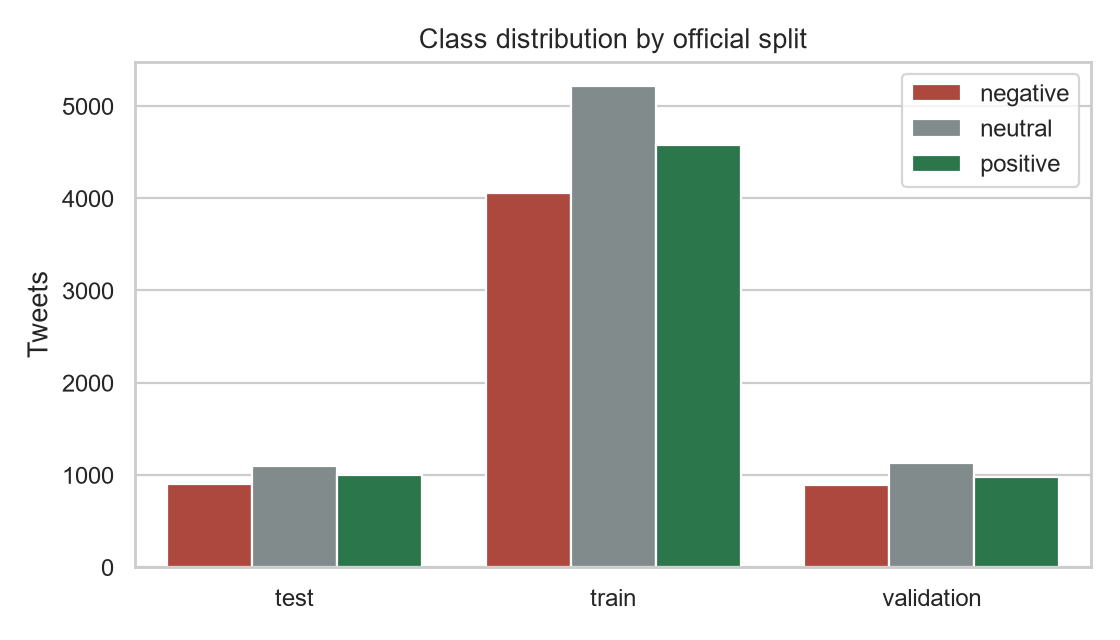

**length_histogram.png**

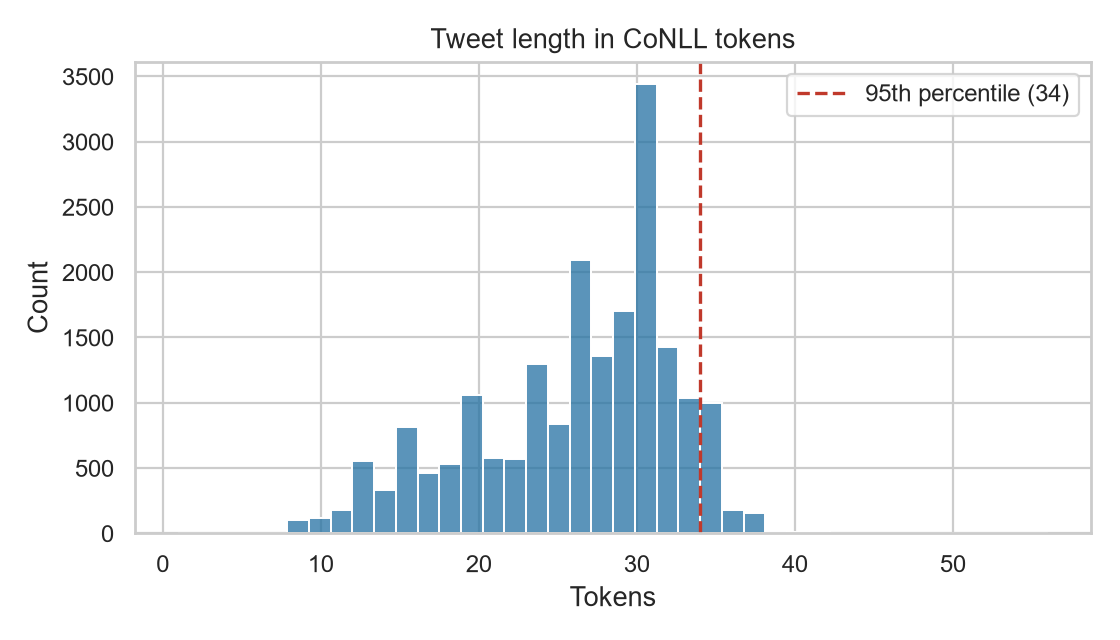

**cmi_distribution.png**

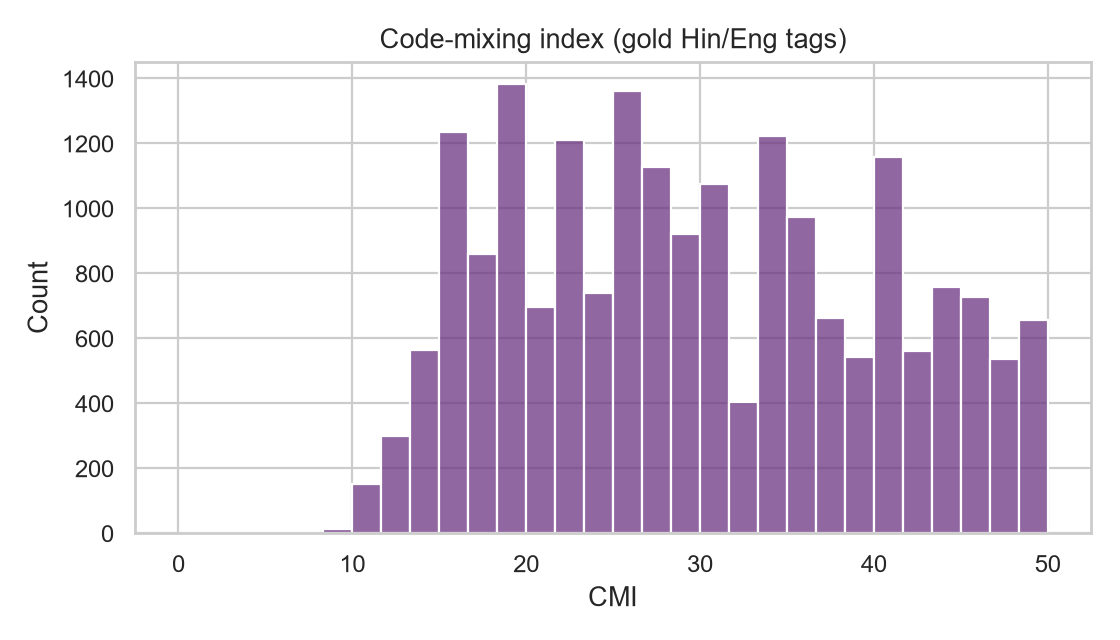

**top_words.png**

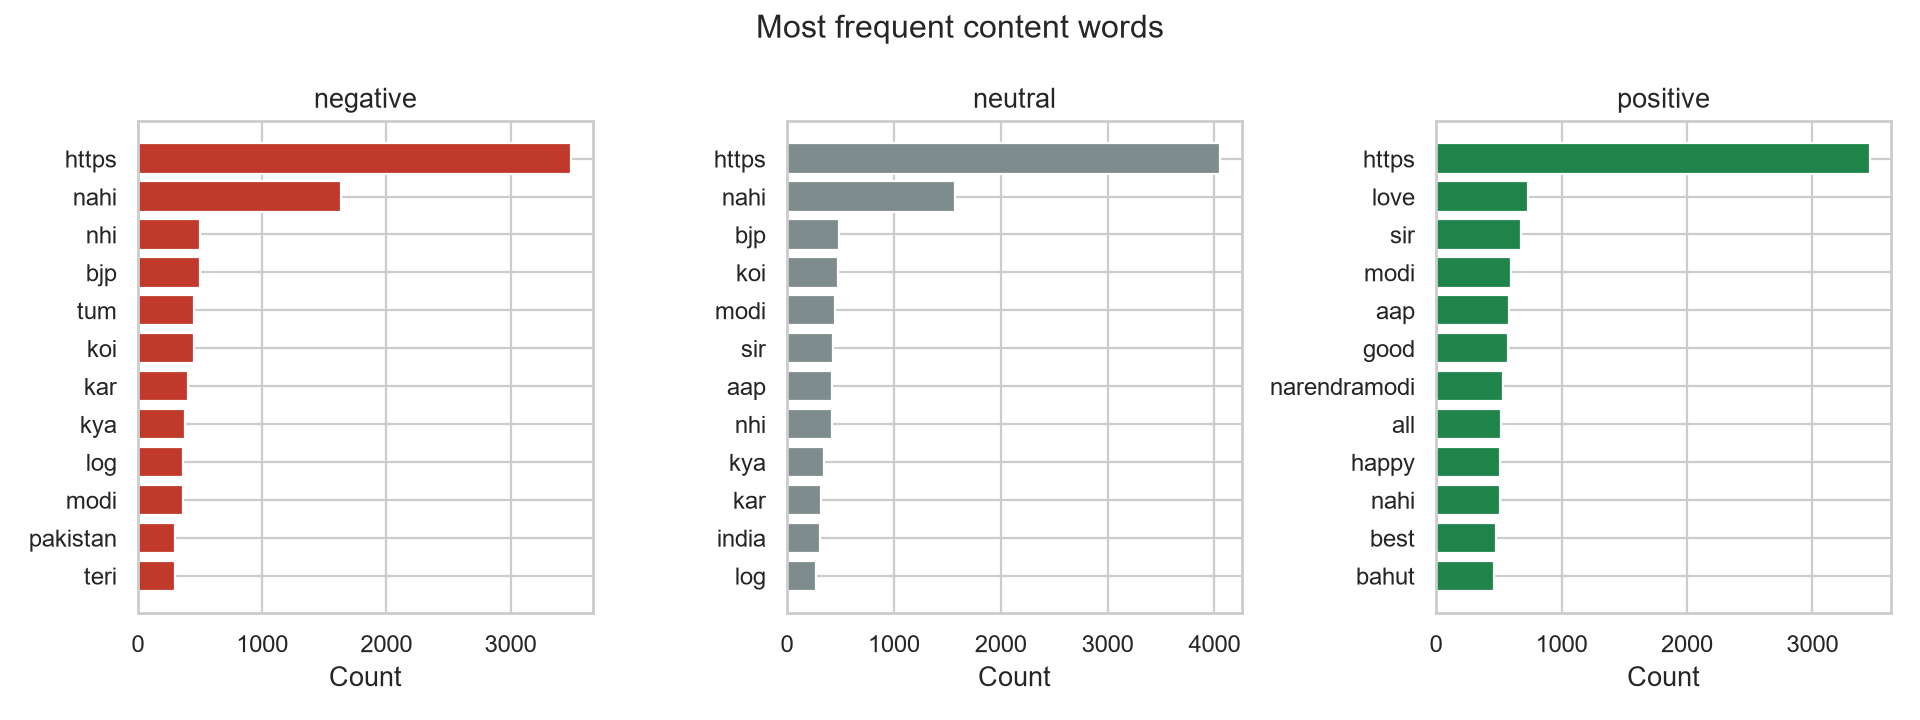

**model_comparison.png**

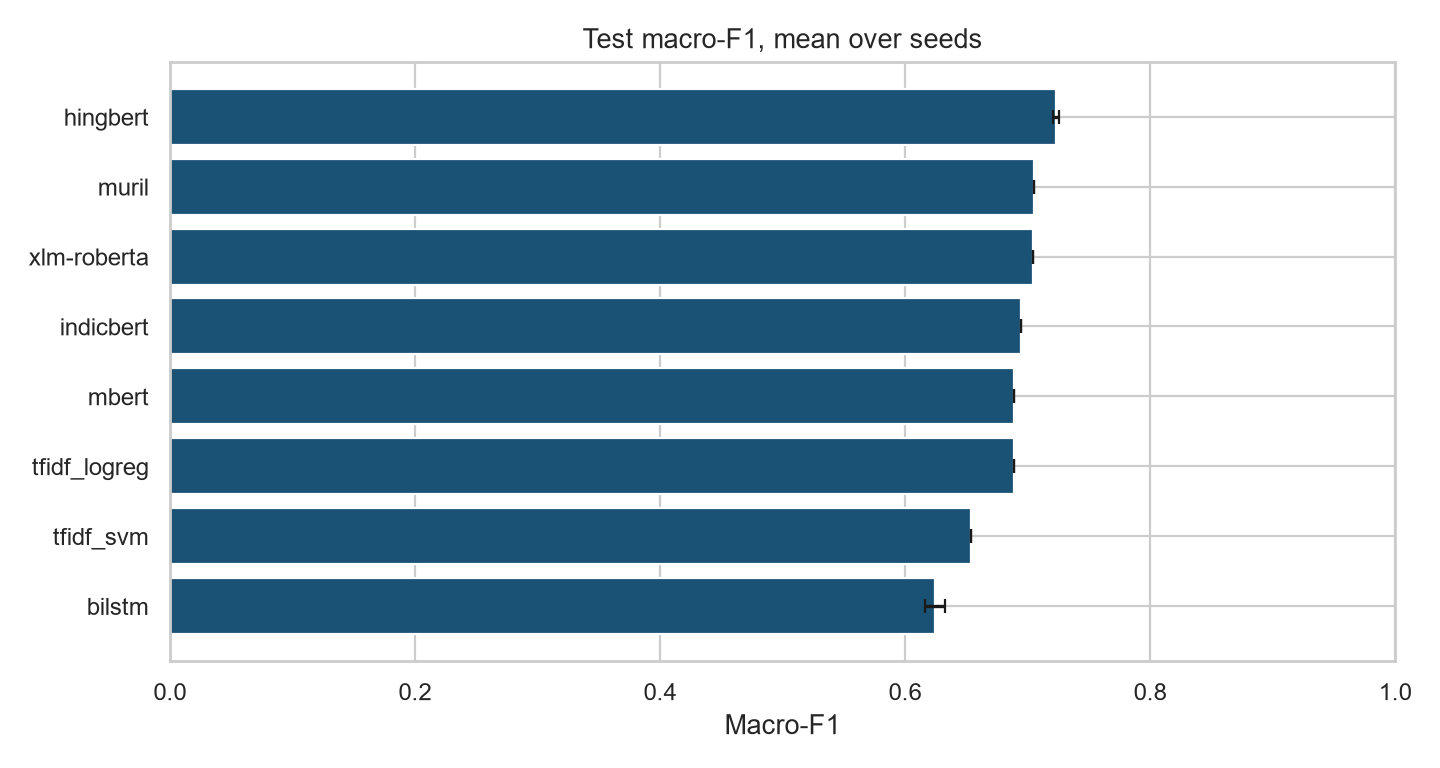

**cm_baseline_logreg.png**

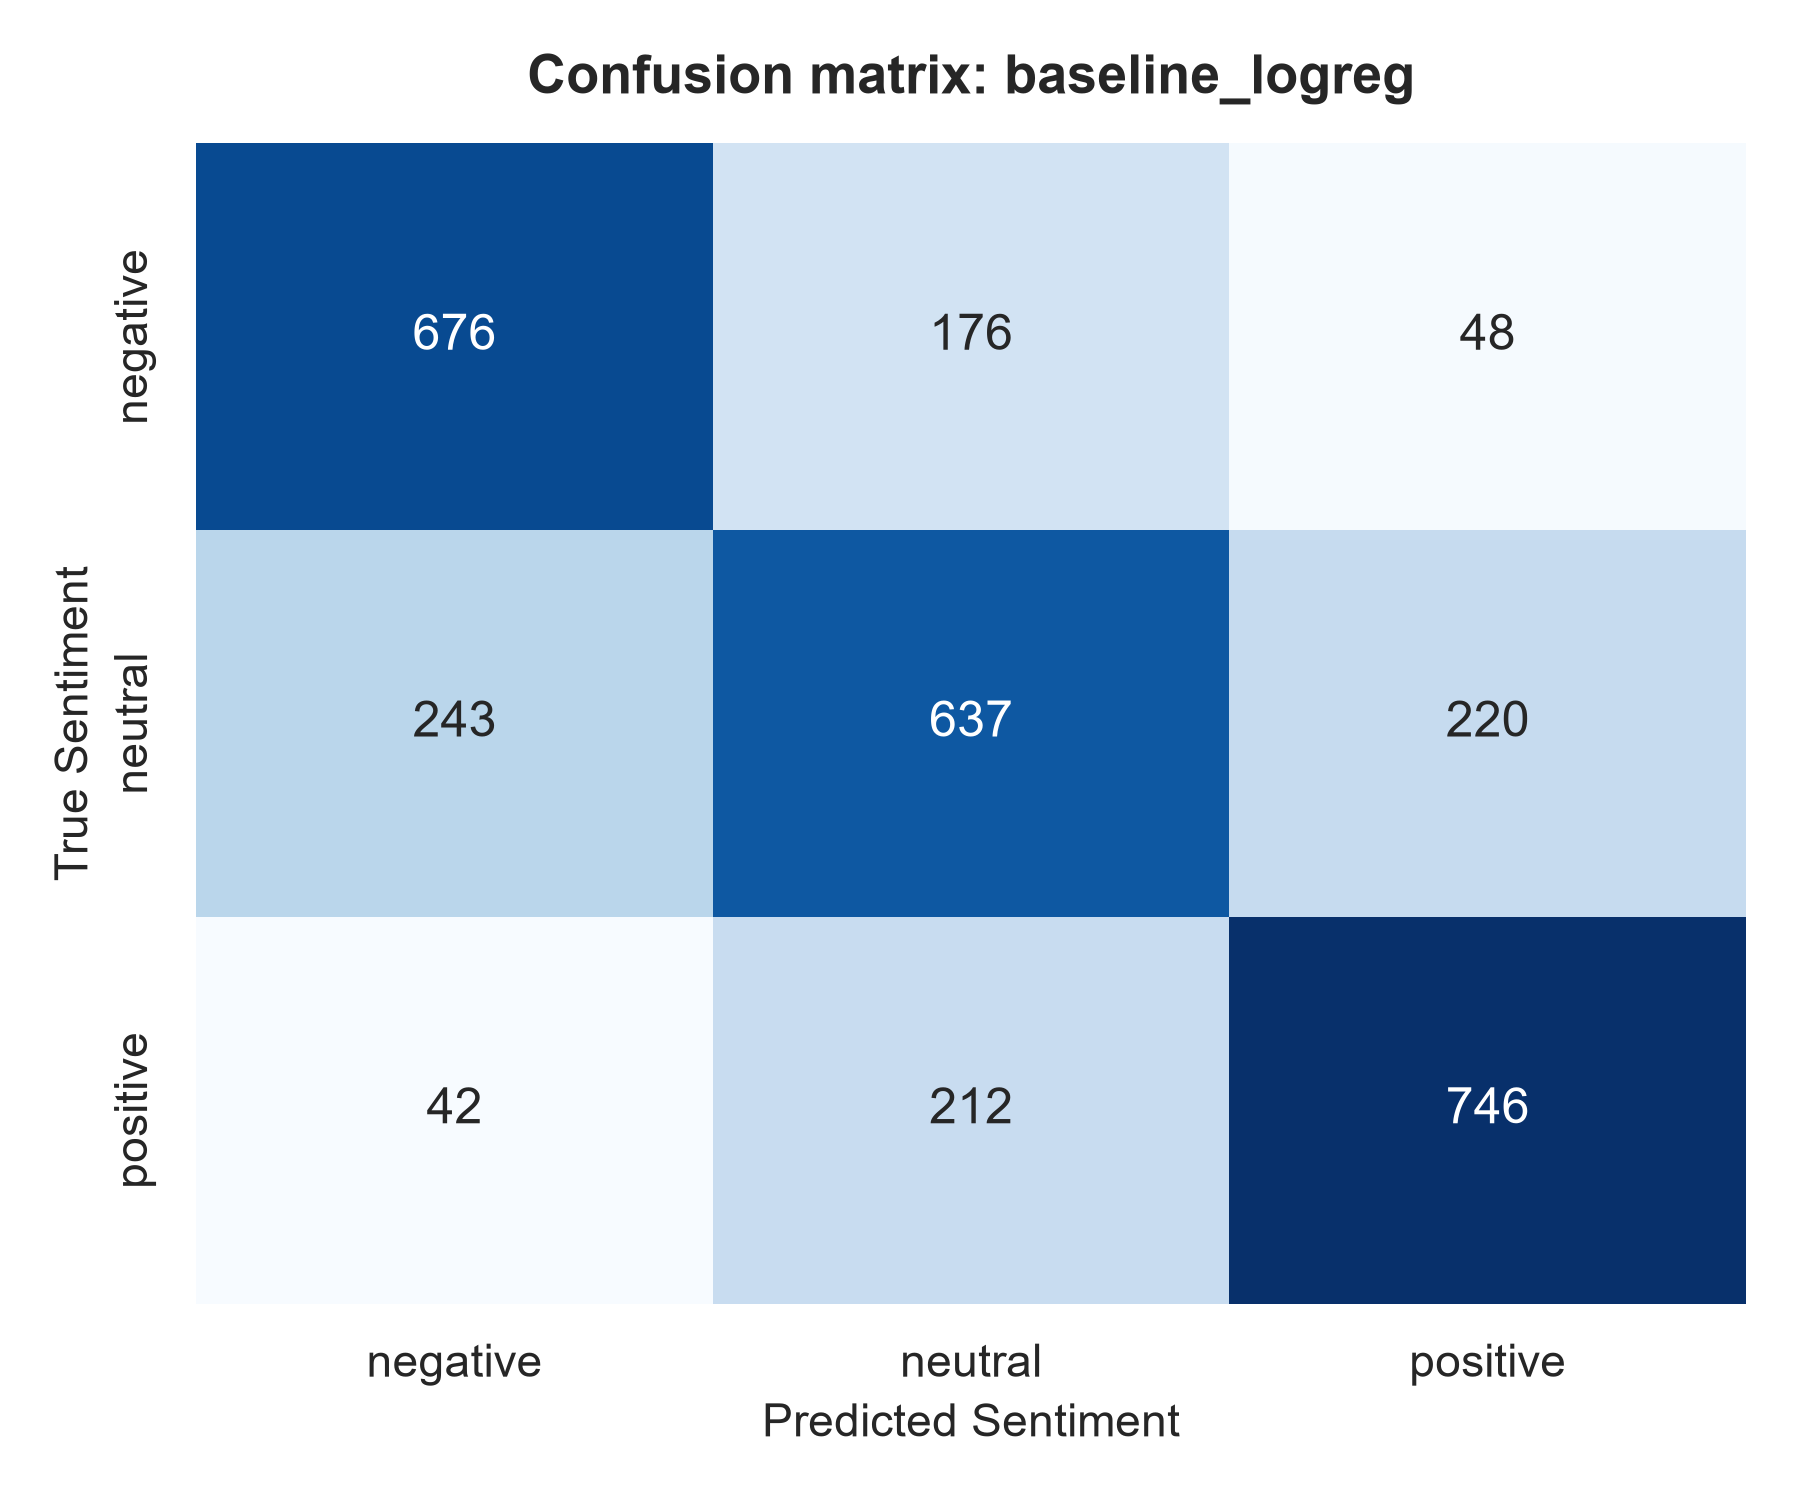

**cm_baseline_svm.png**

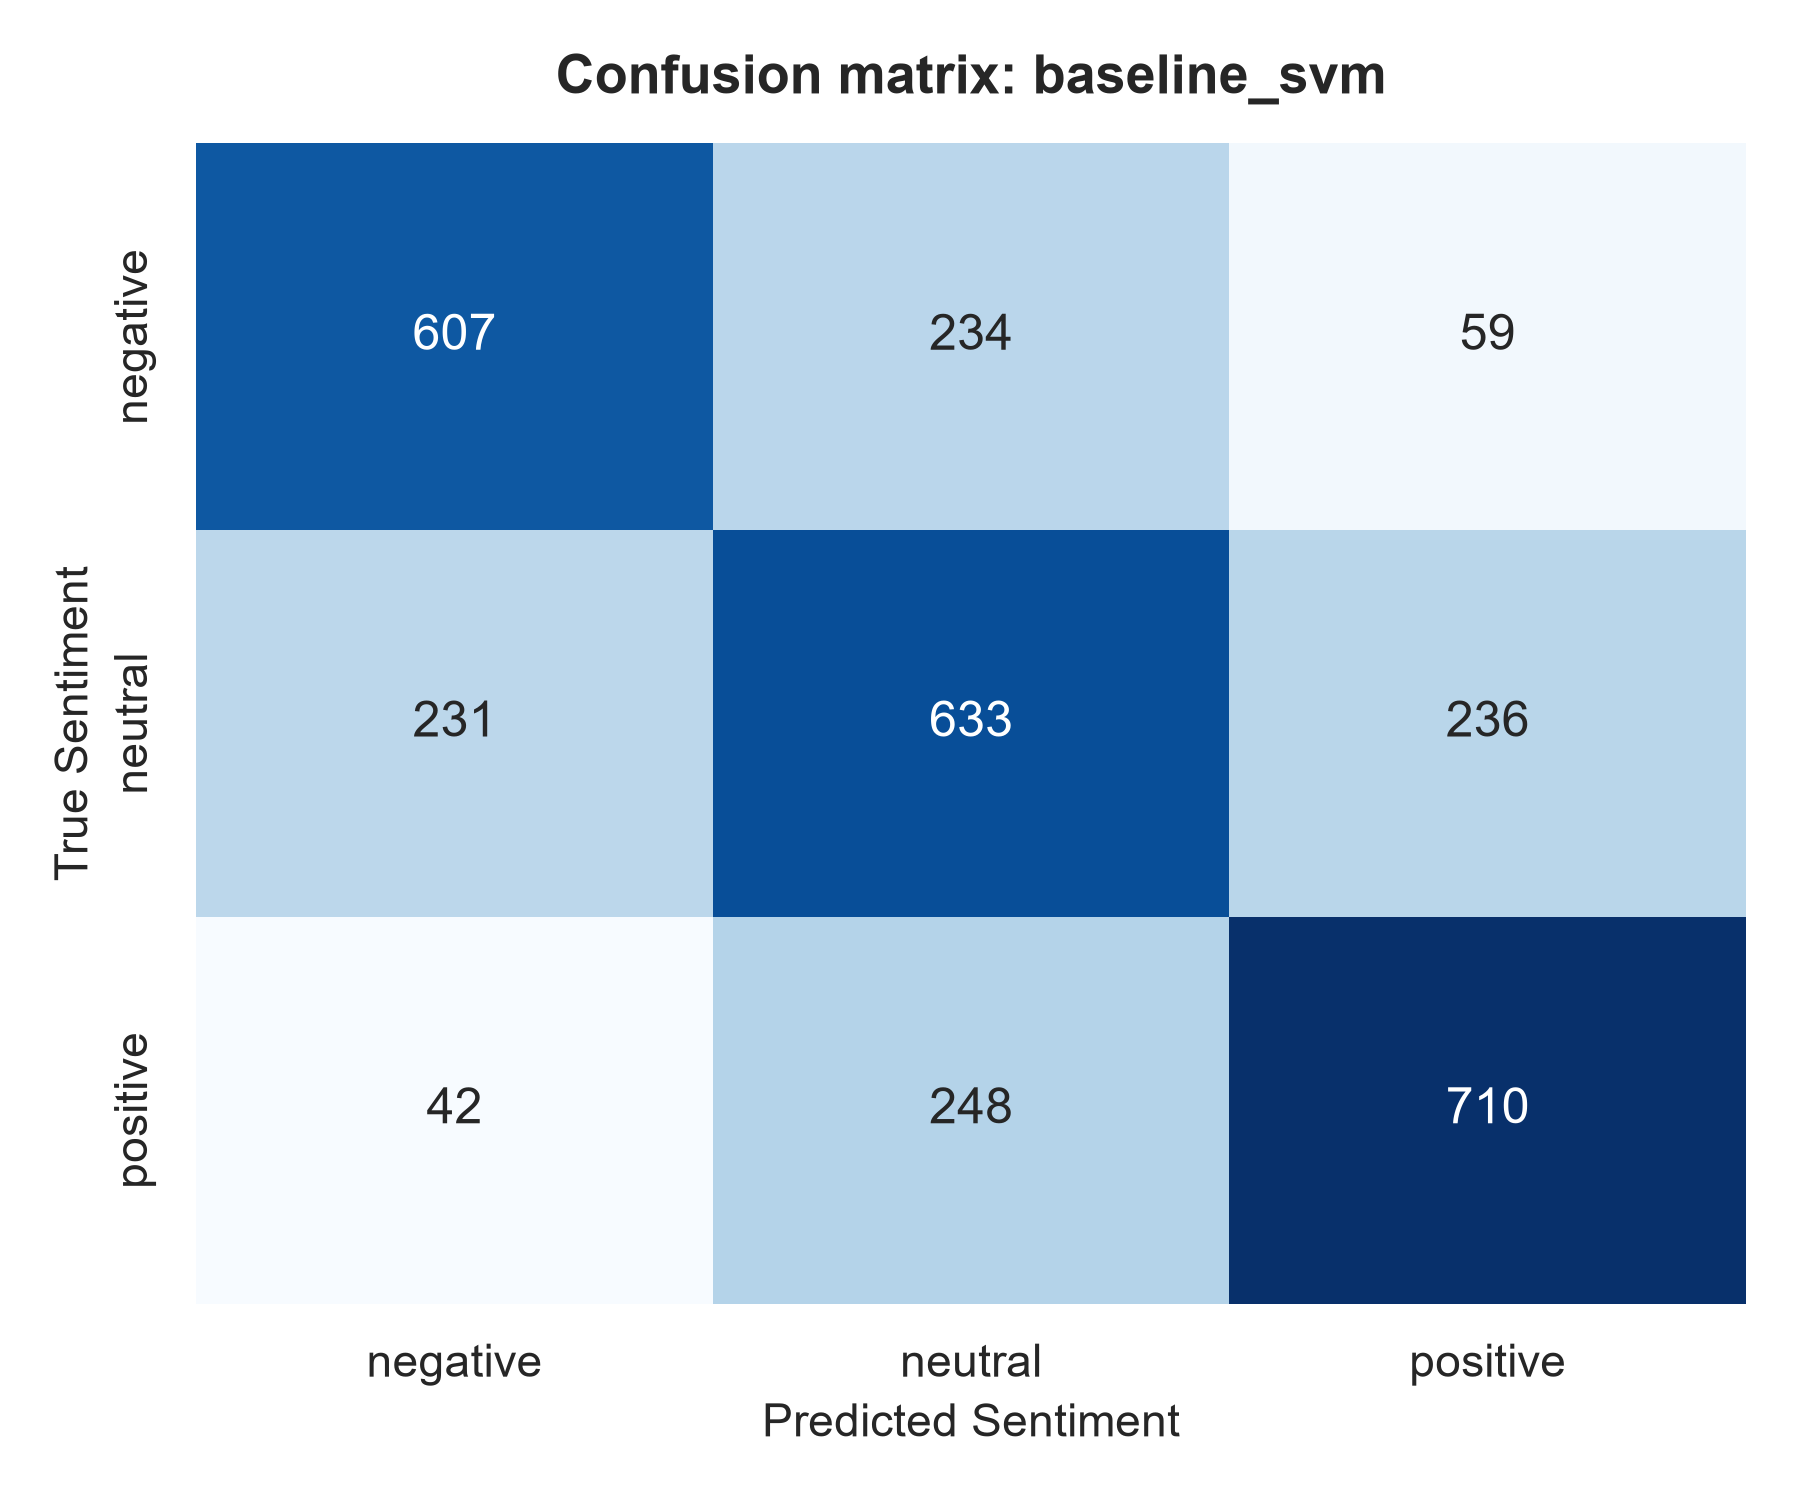

**cm_bilstm.png**

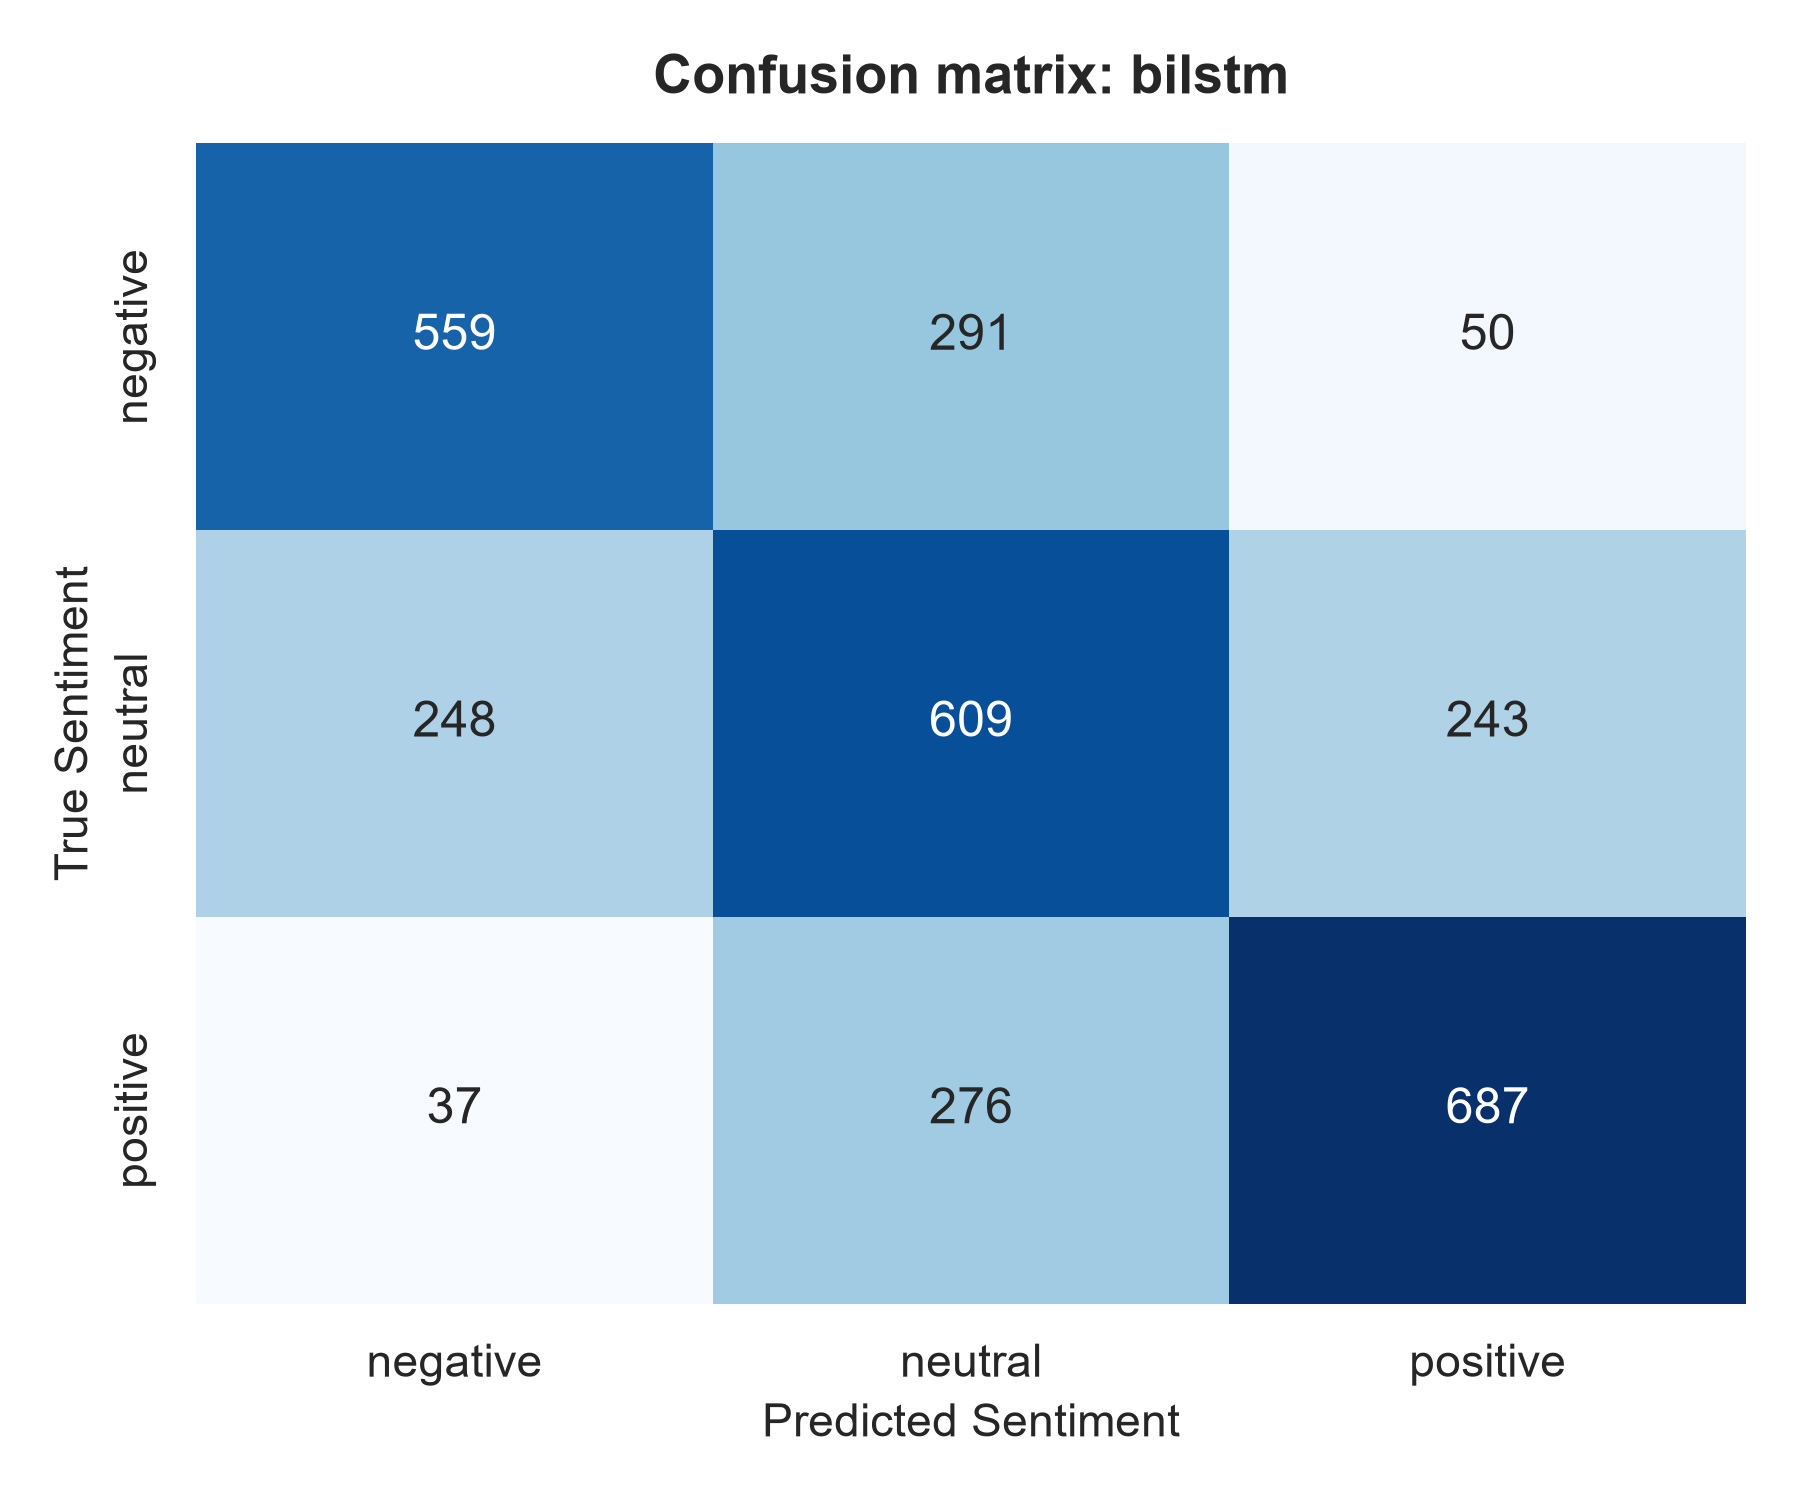

**cm_hingbert.png**

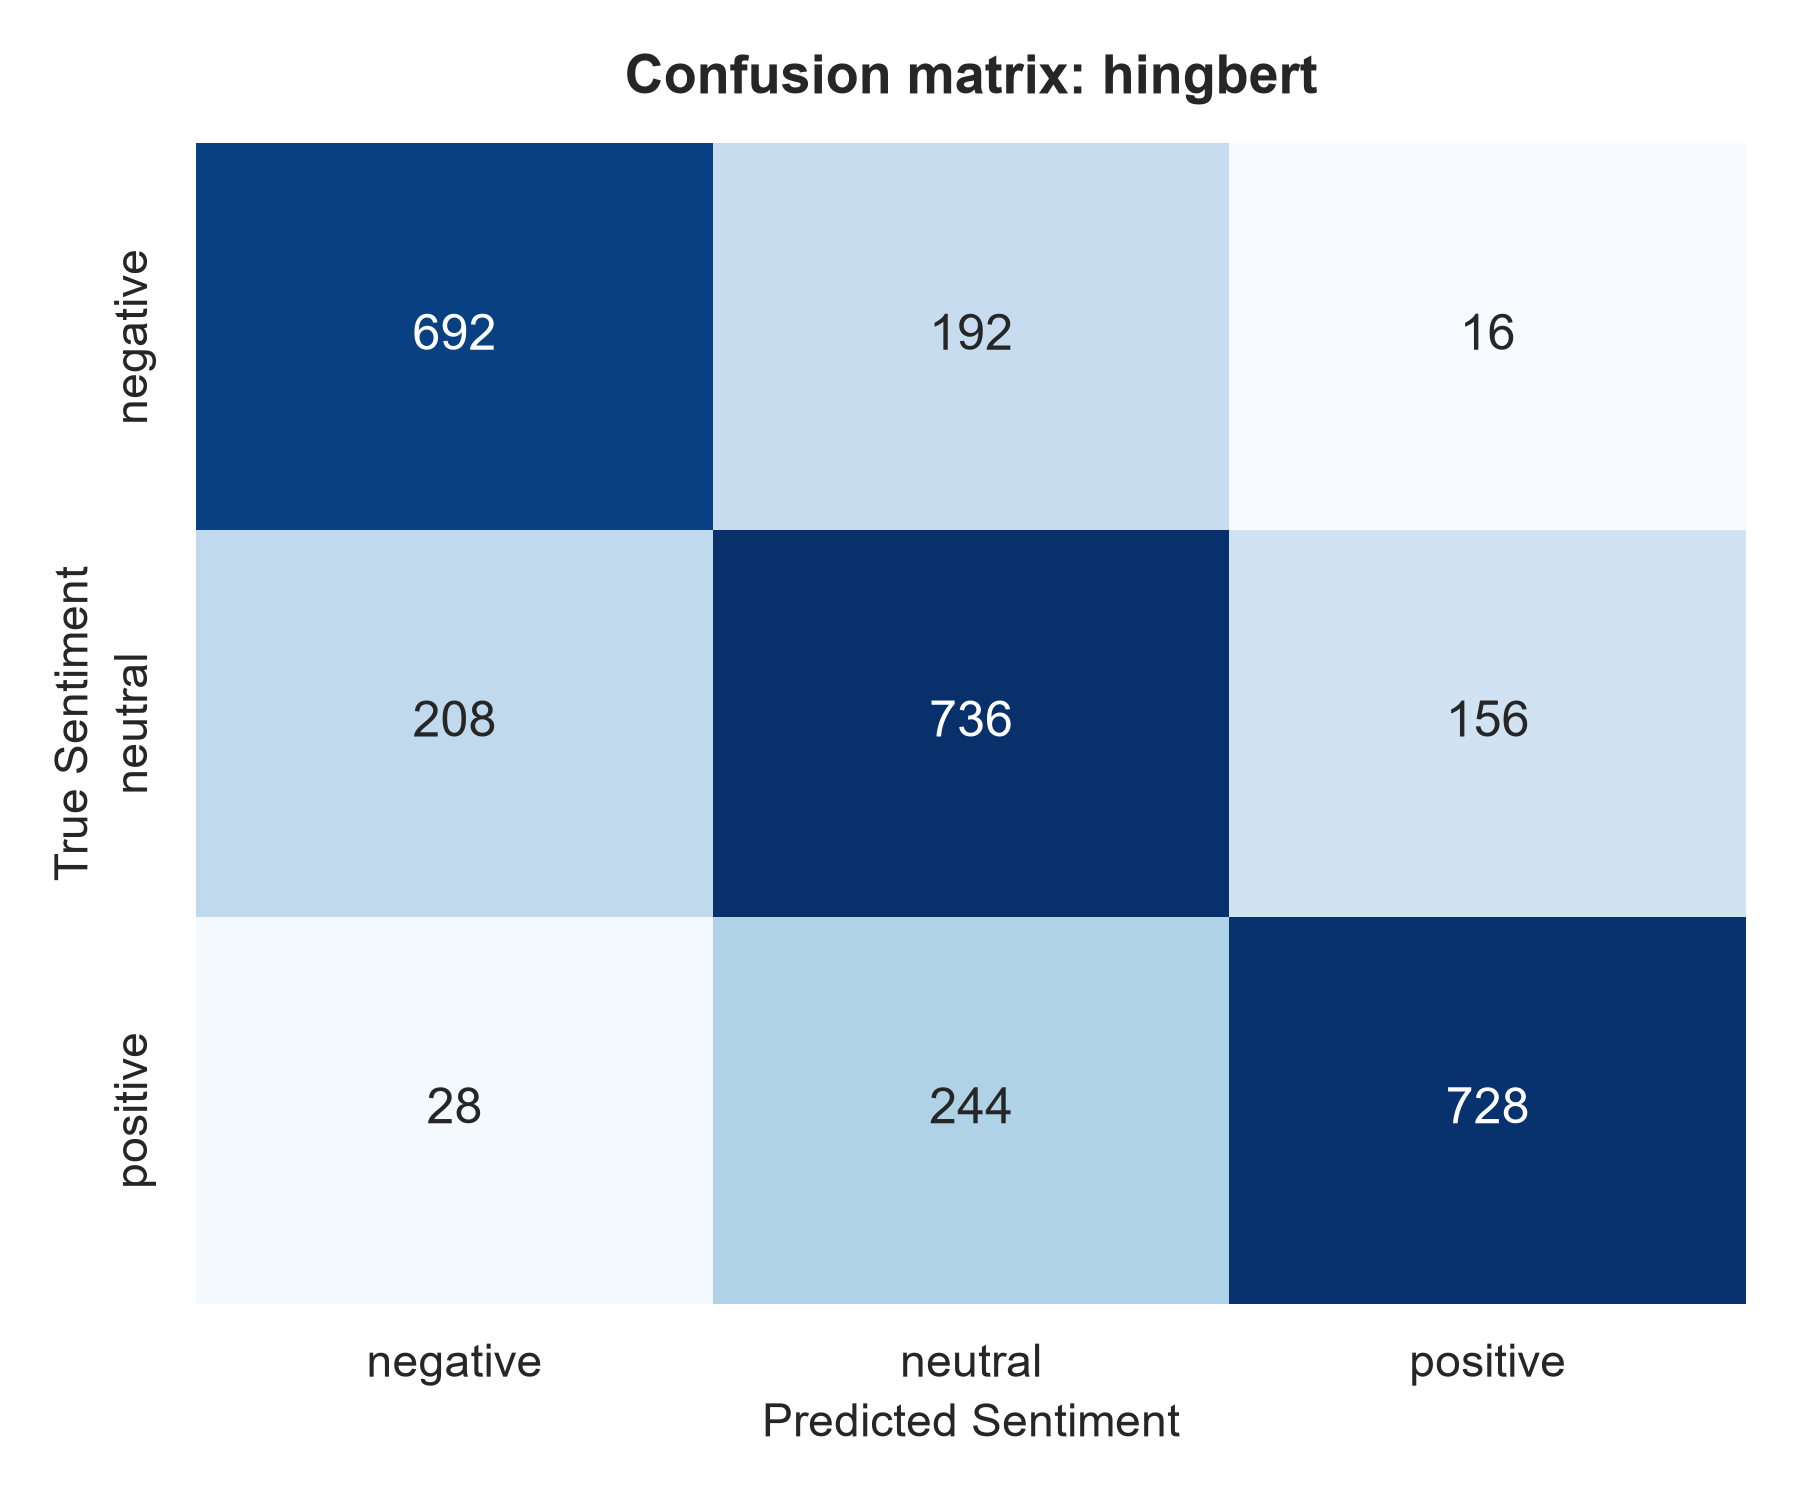

**cm_indicbert.png**

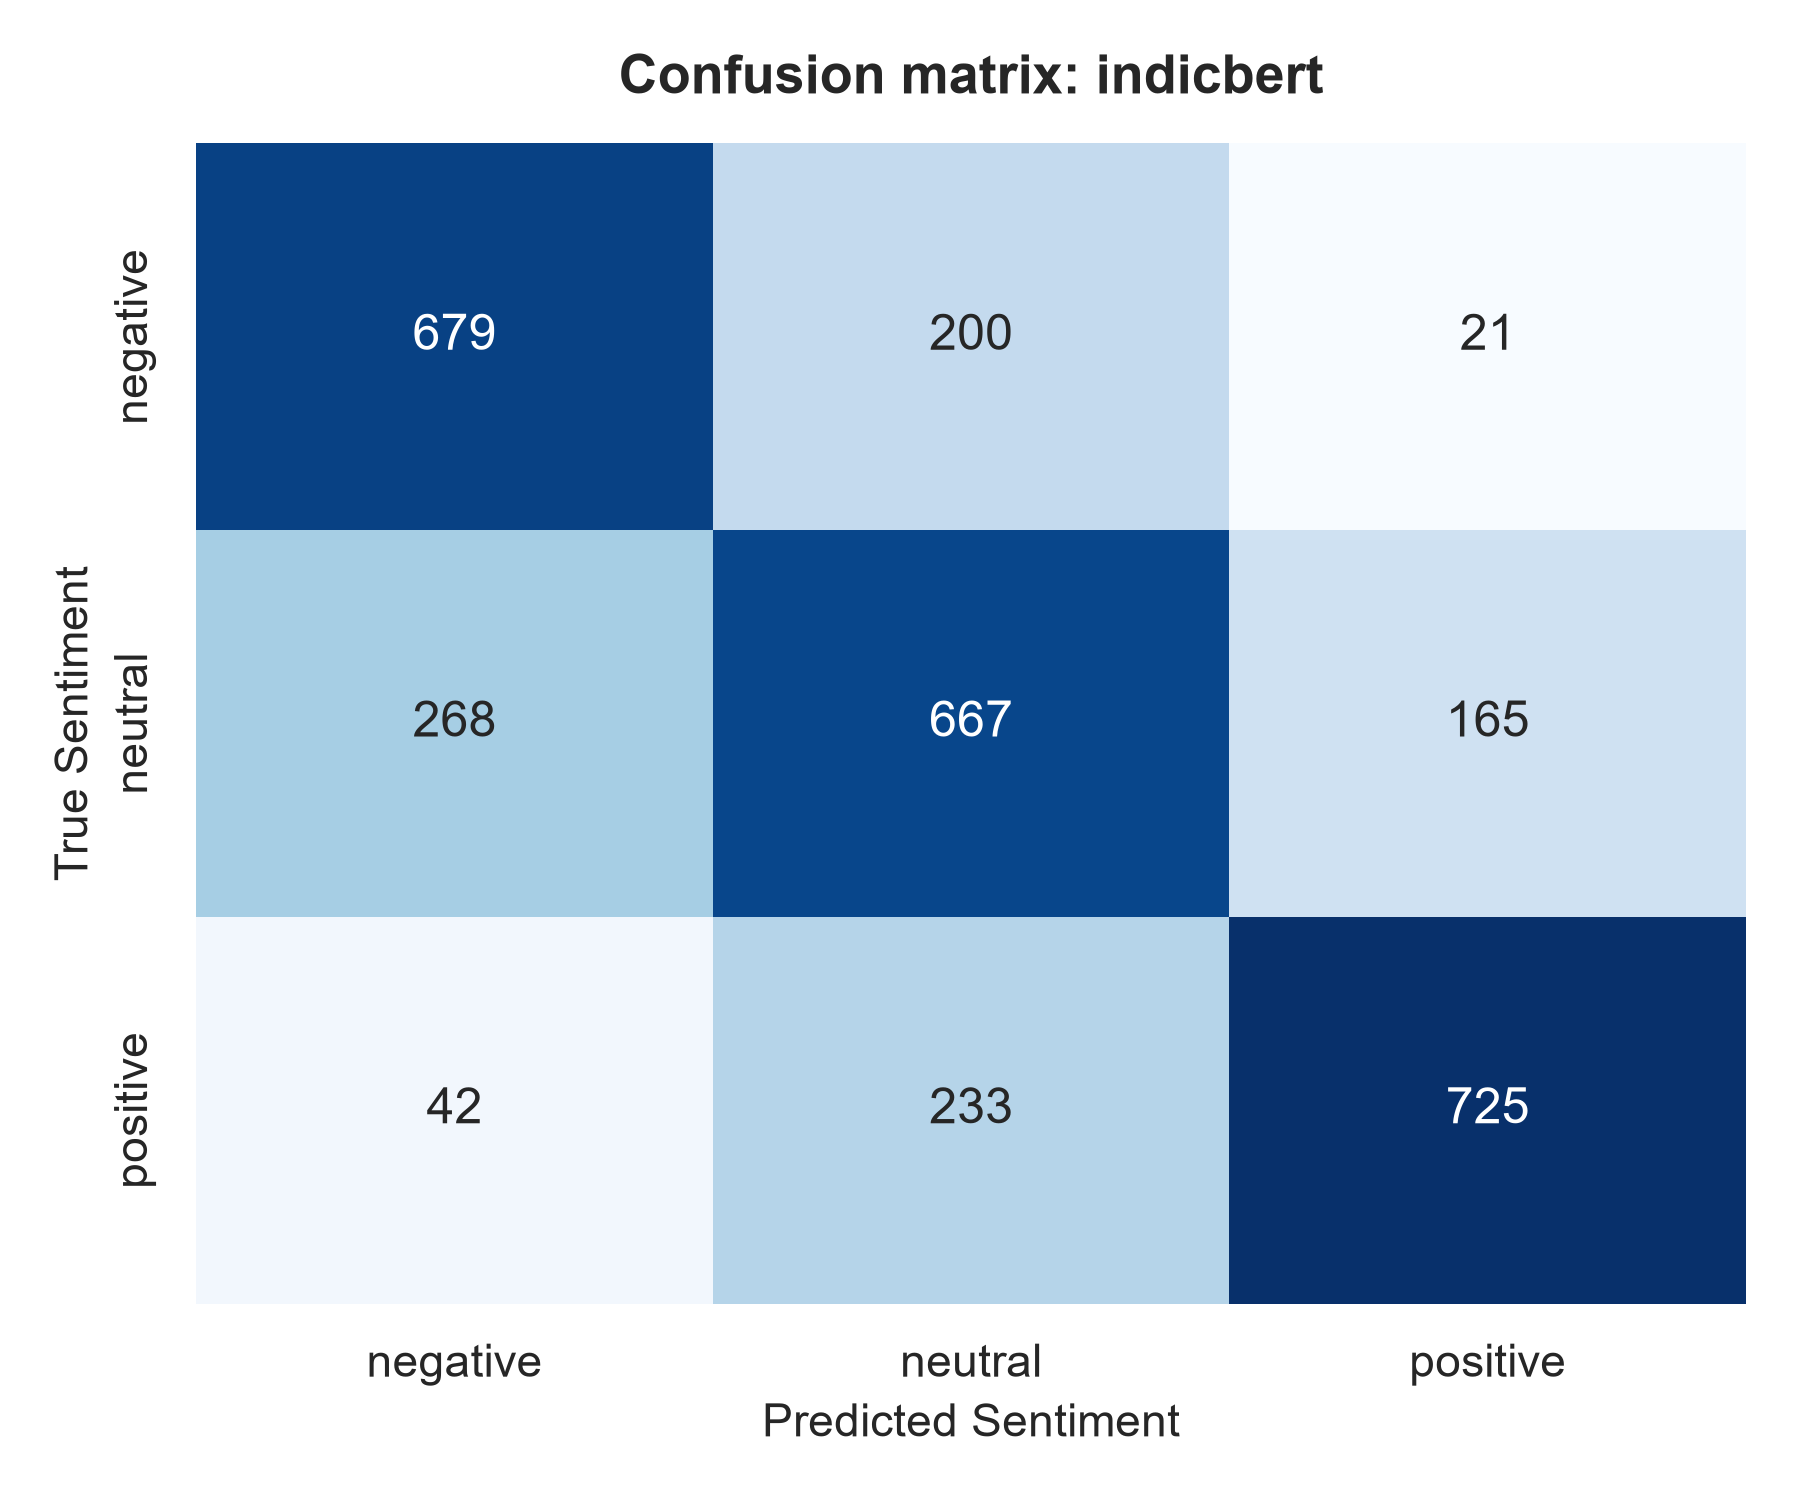

**cm_mbert.png**

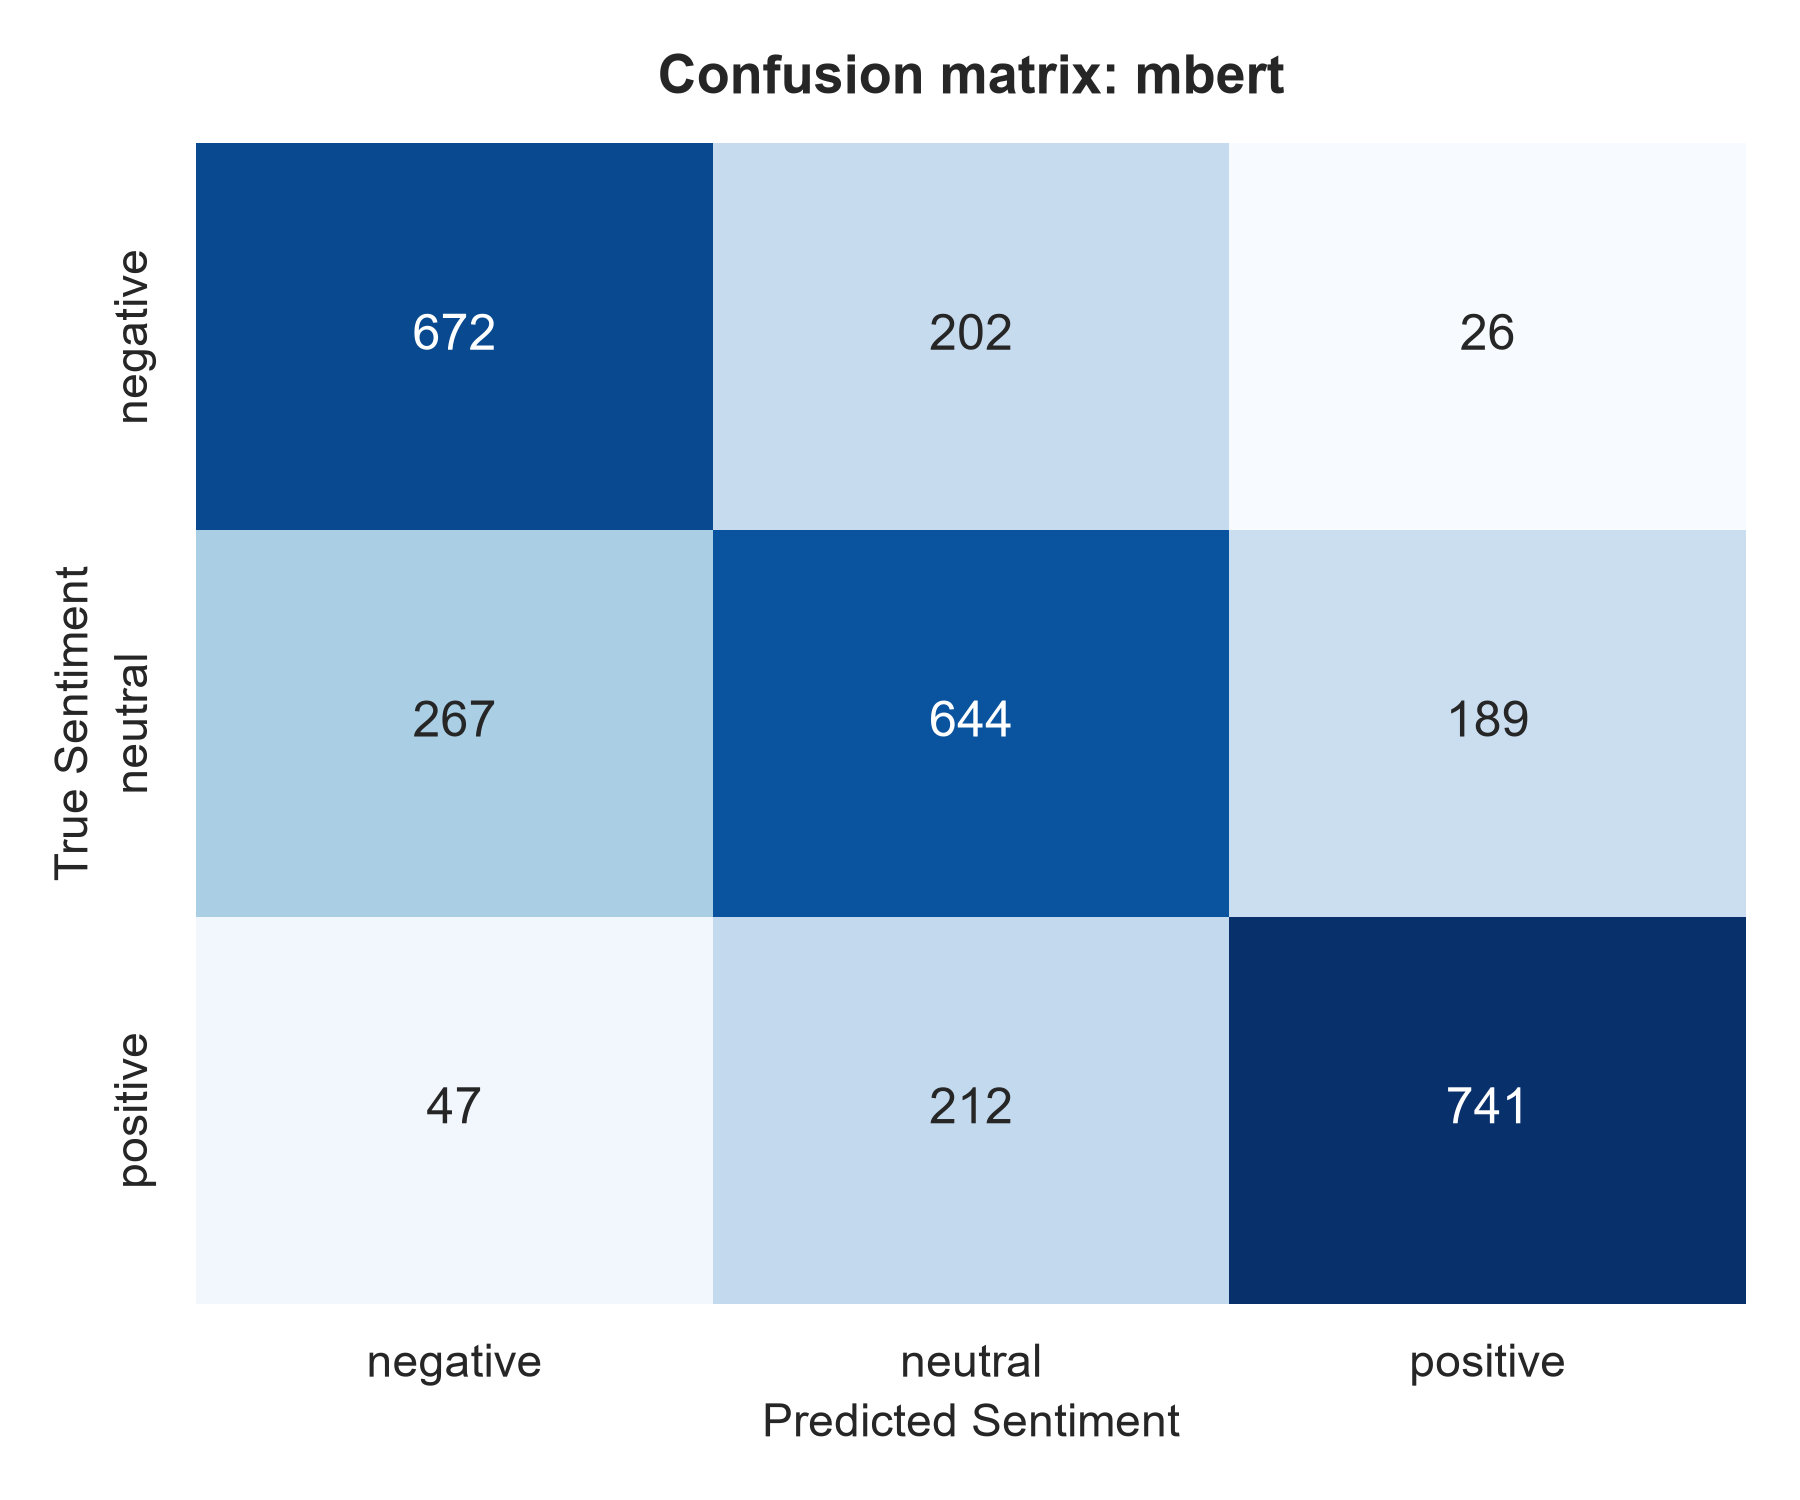

**cm_muril.png**

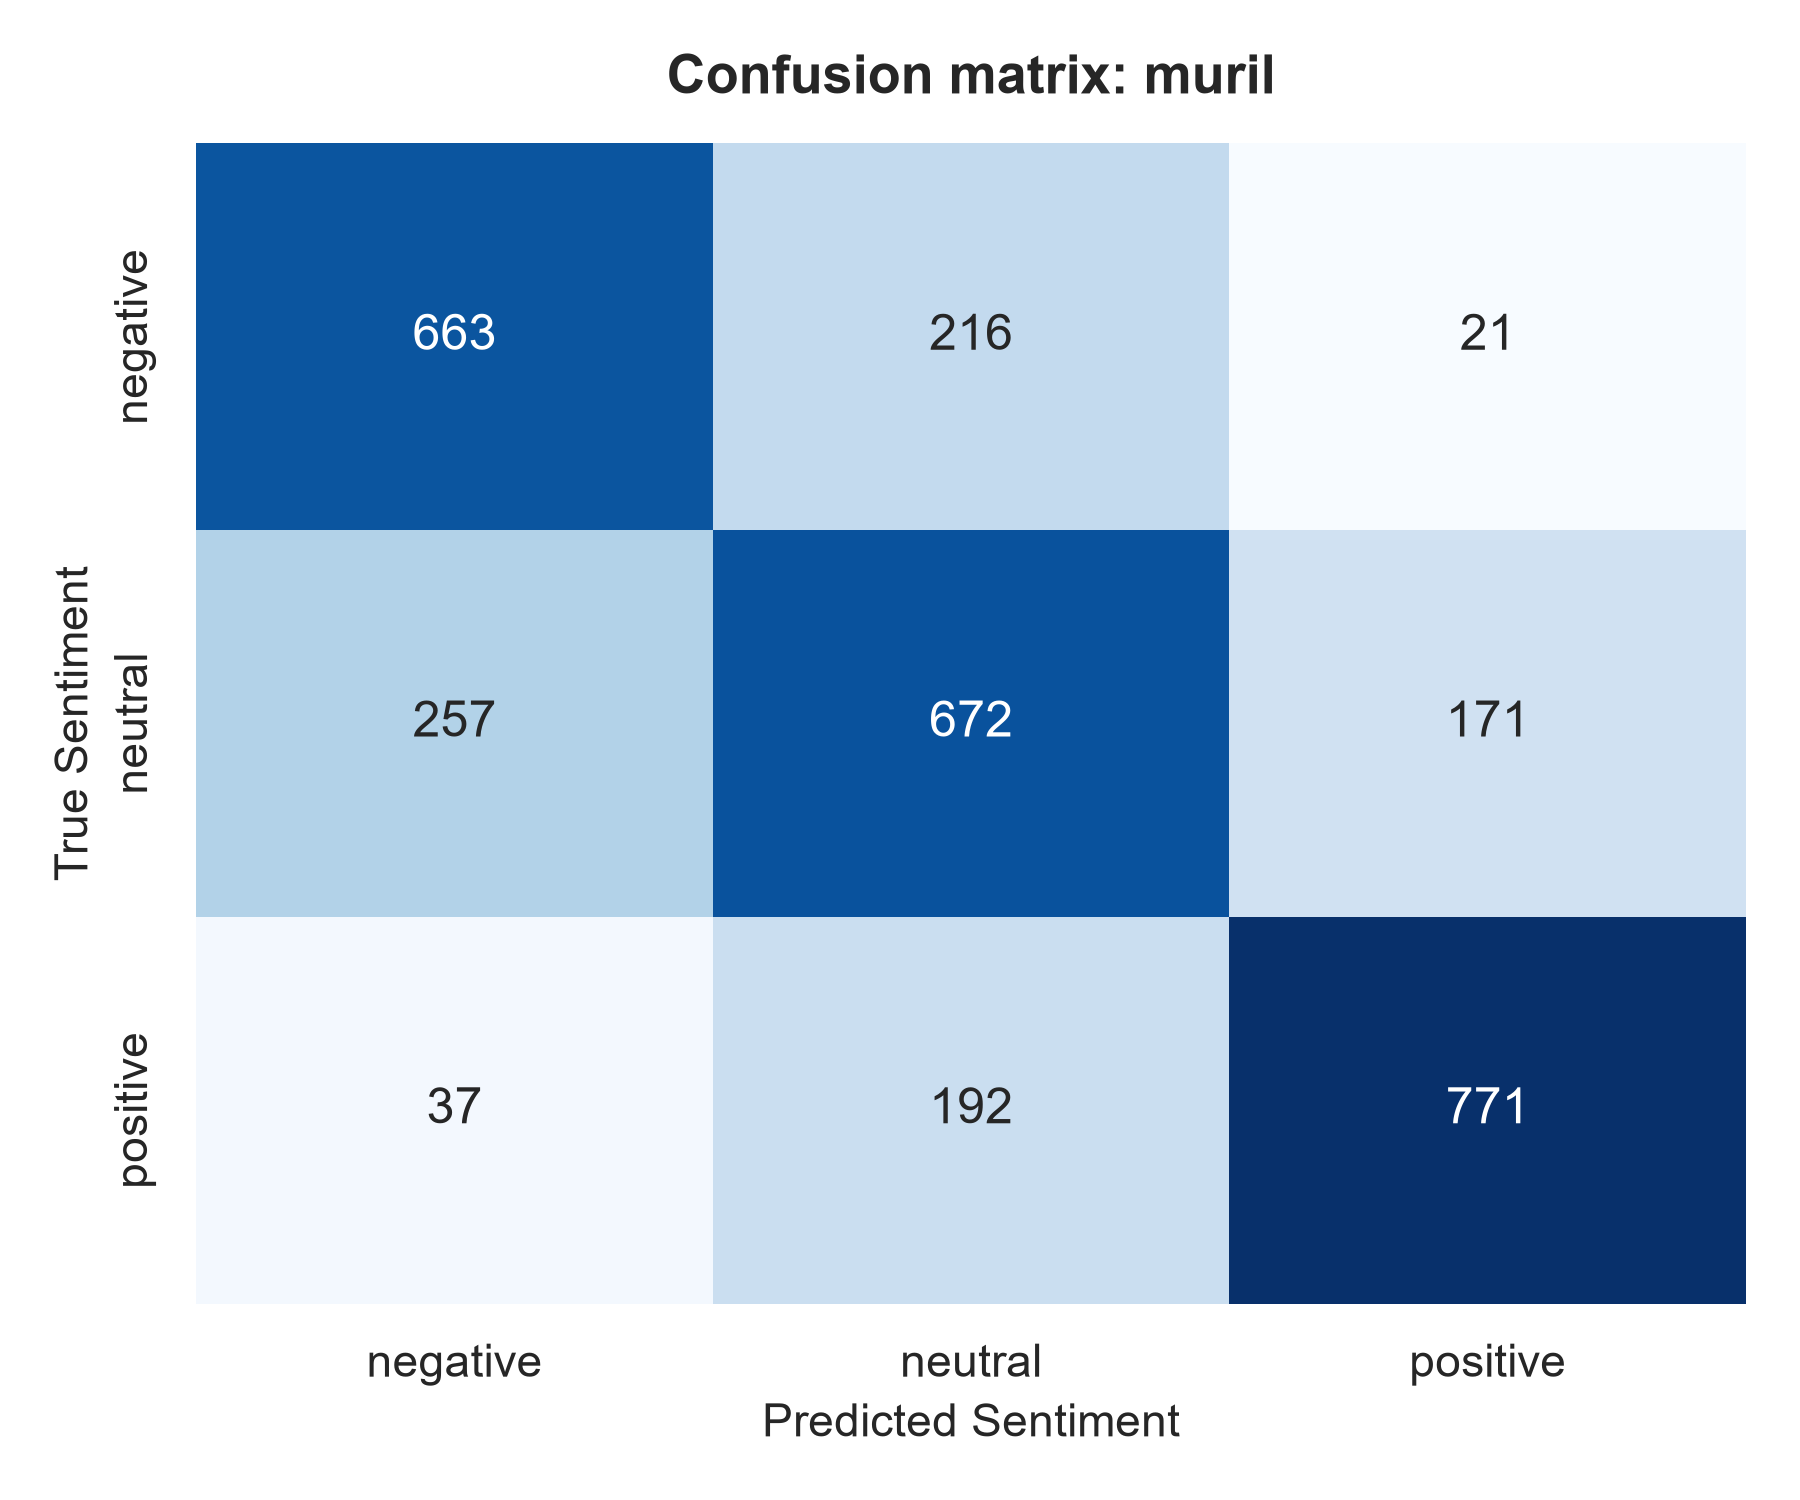

**cm_tfidf_logreg.png**

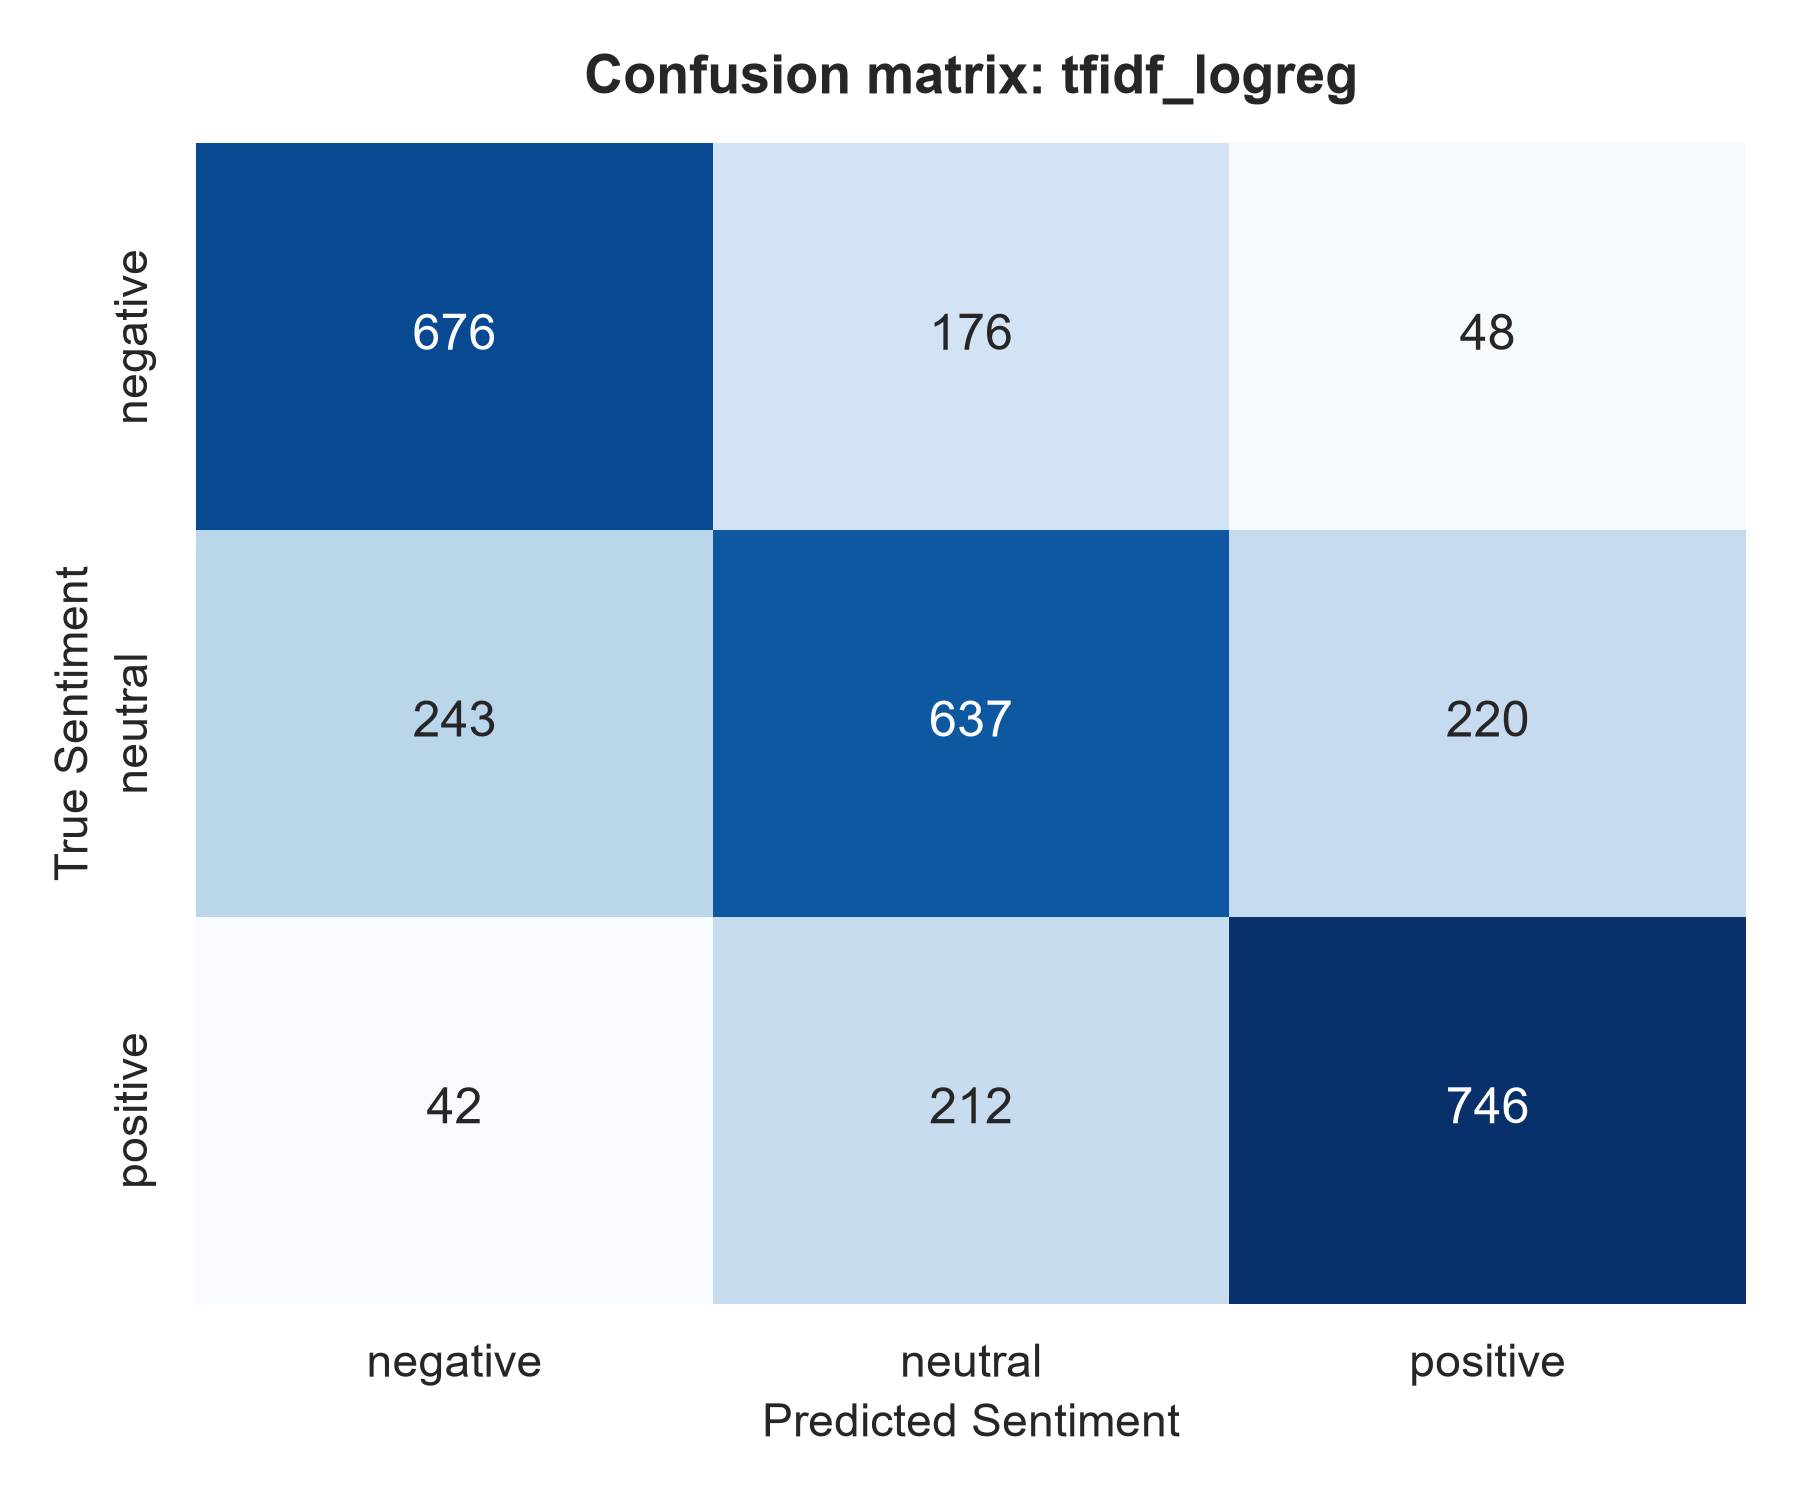

**cm_tfidf_svm.png**

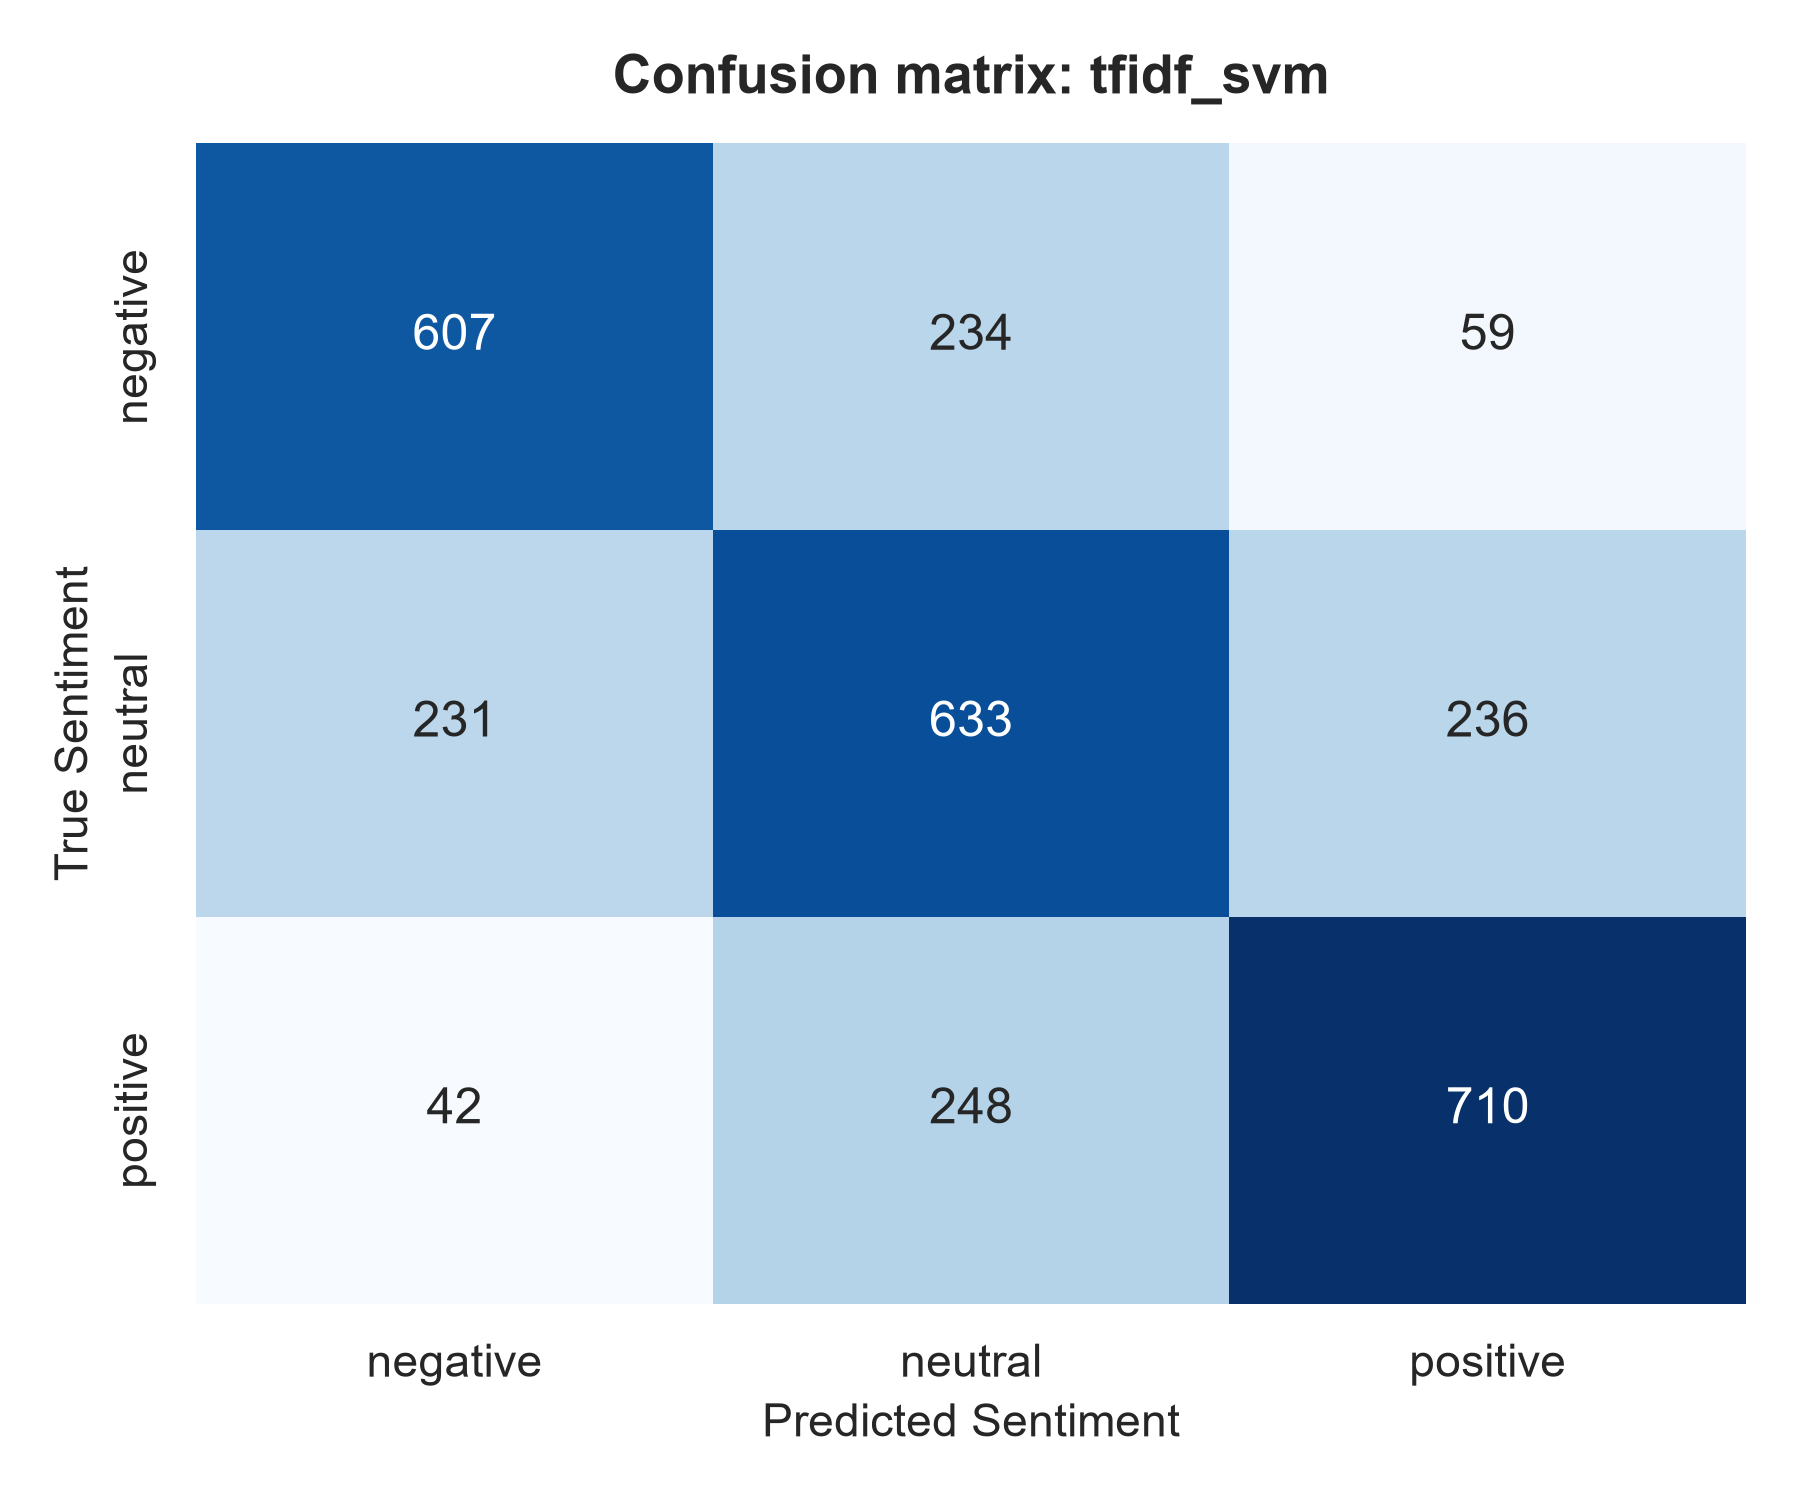

**cm_xlm-roberta.png**

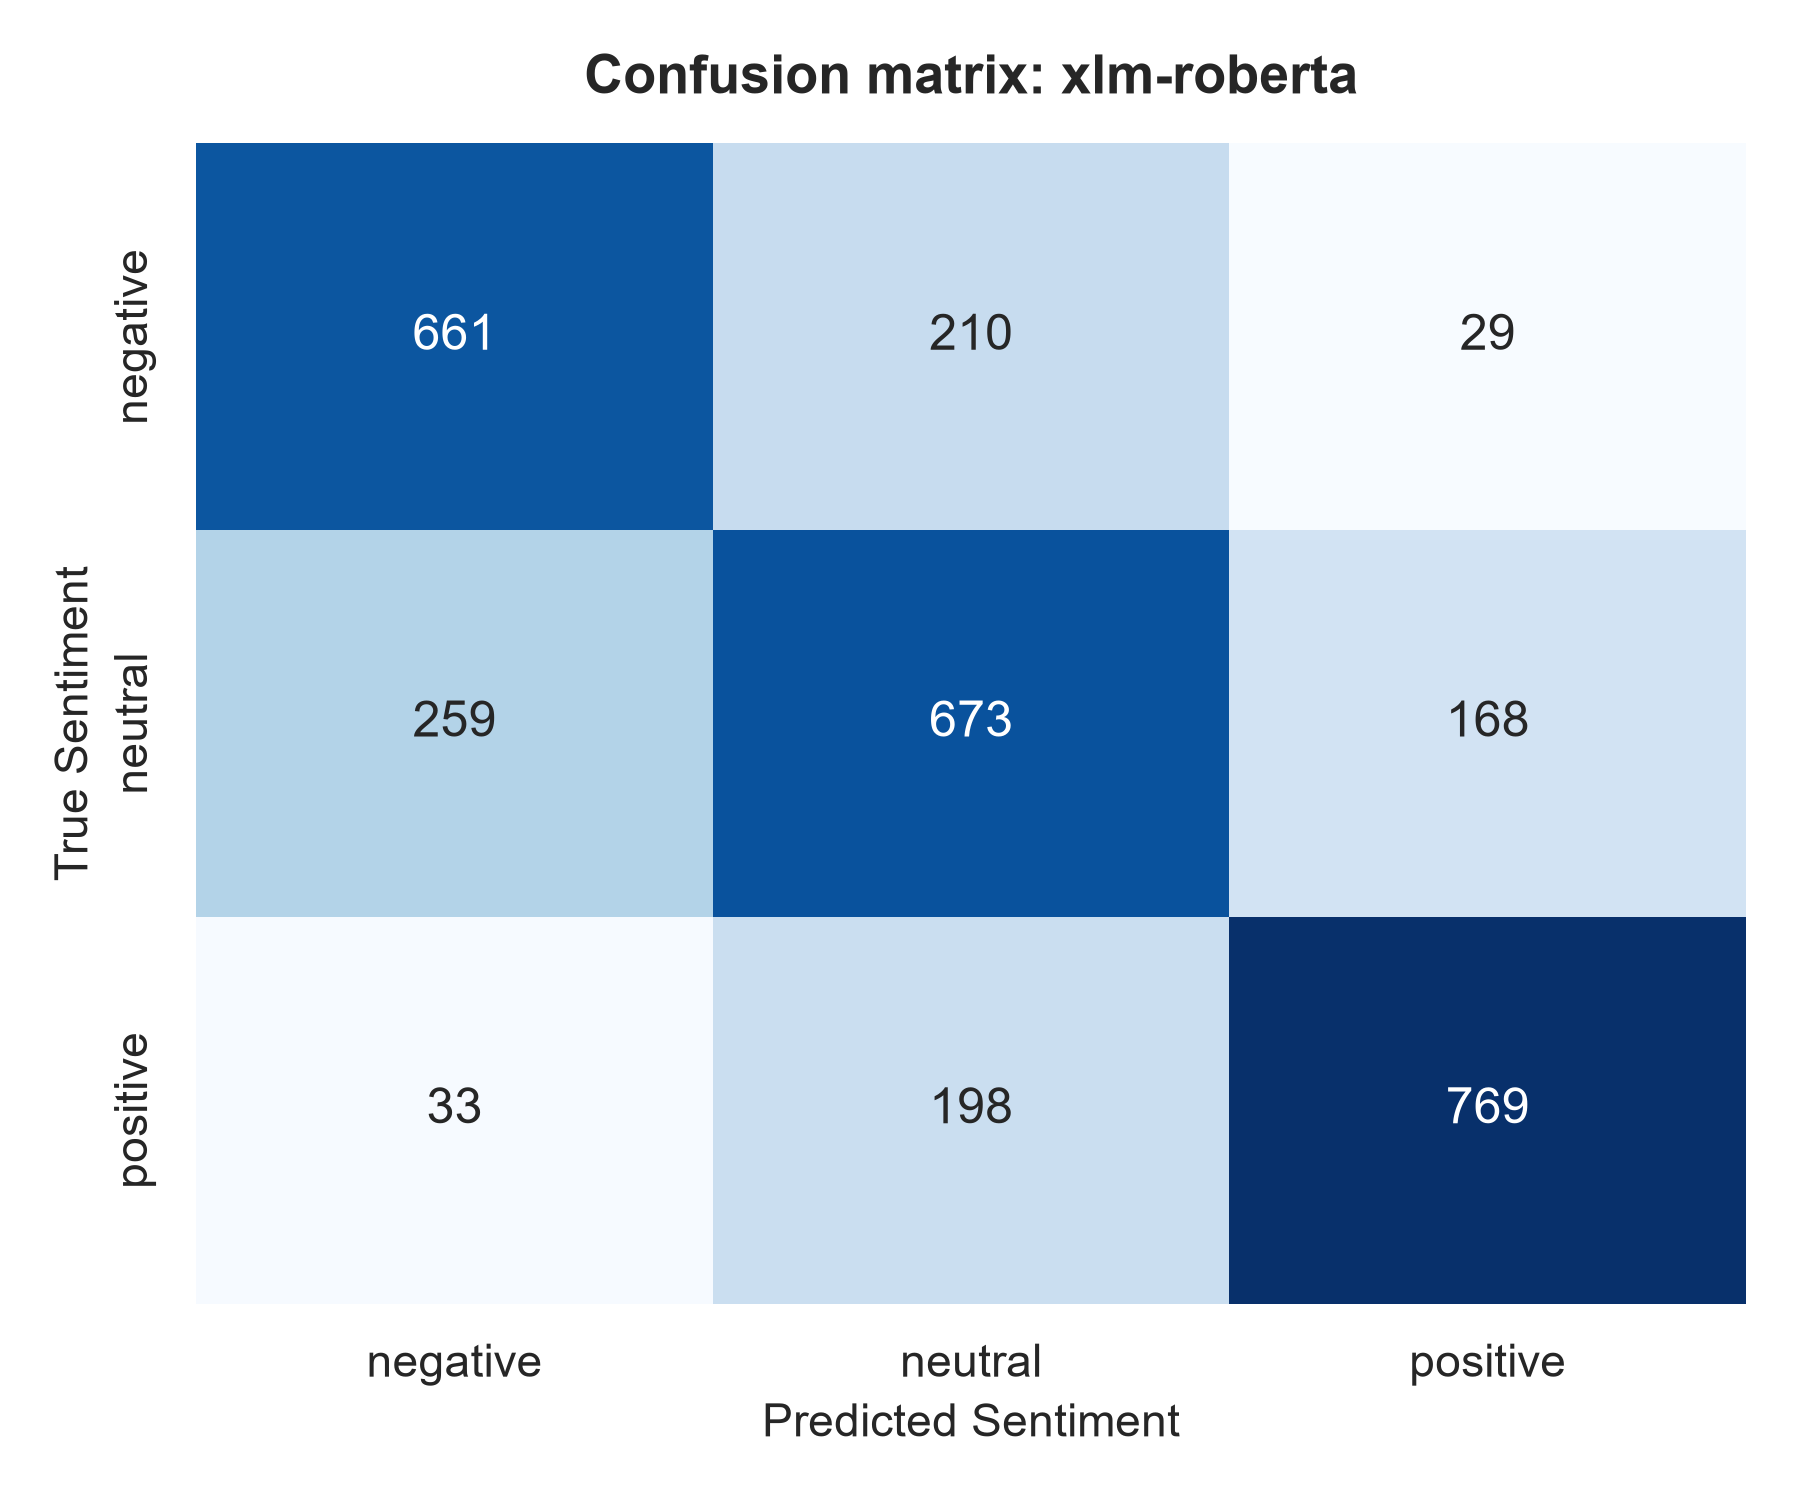

**curves_bilstm.png**

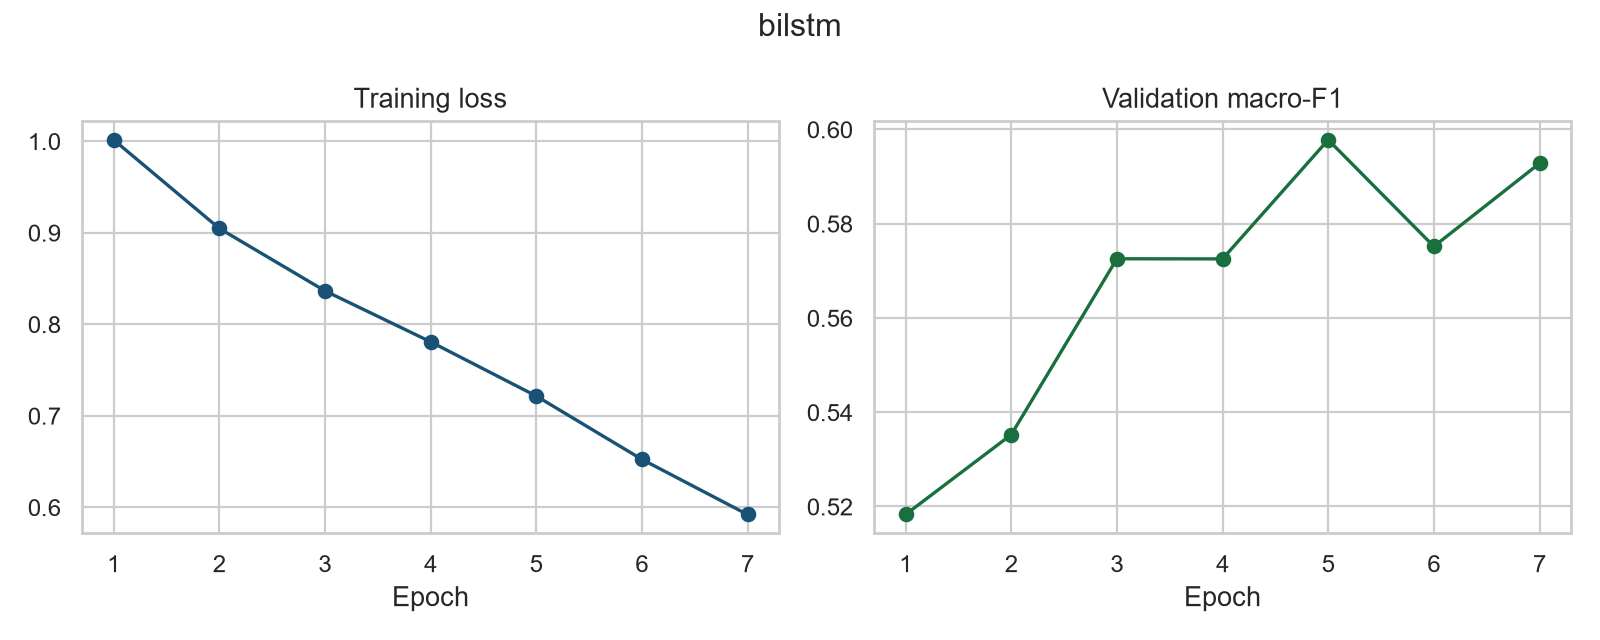

**curves_hingbert.png**

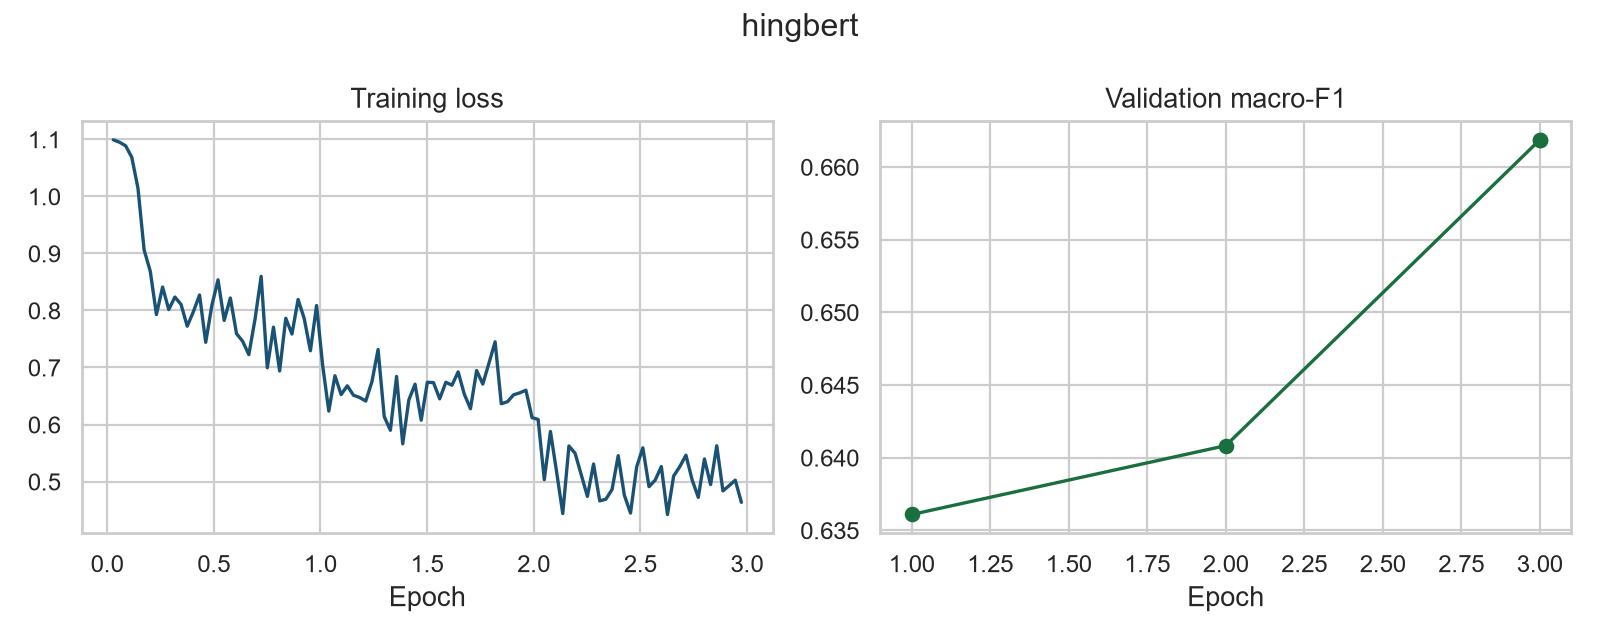

**curves_indicbert.png**

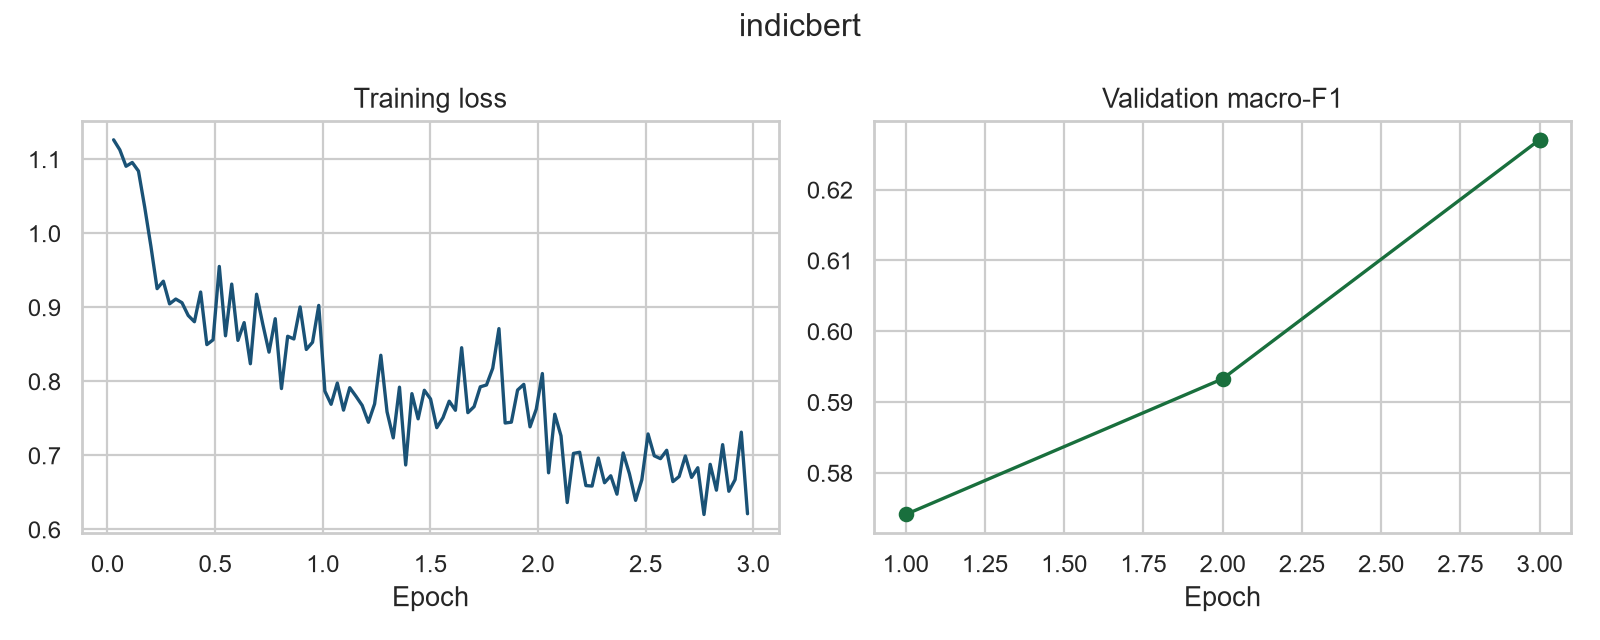

**curves_mbert.png**

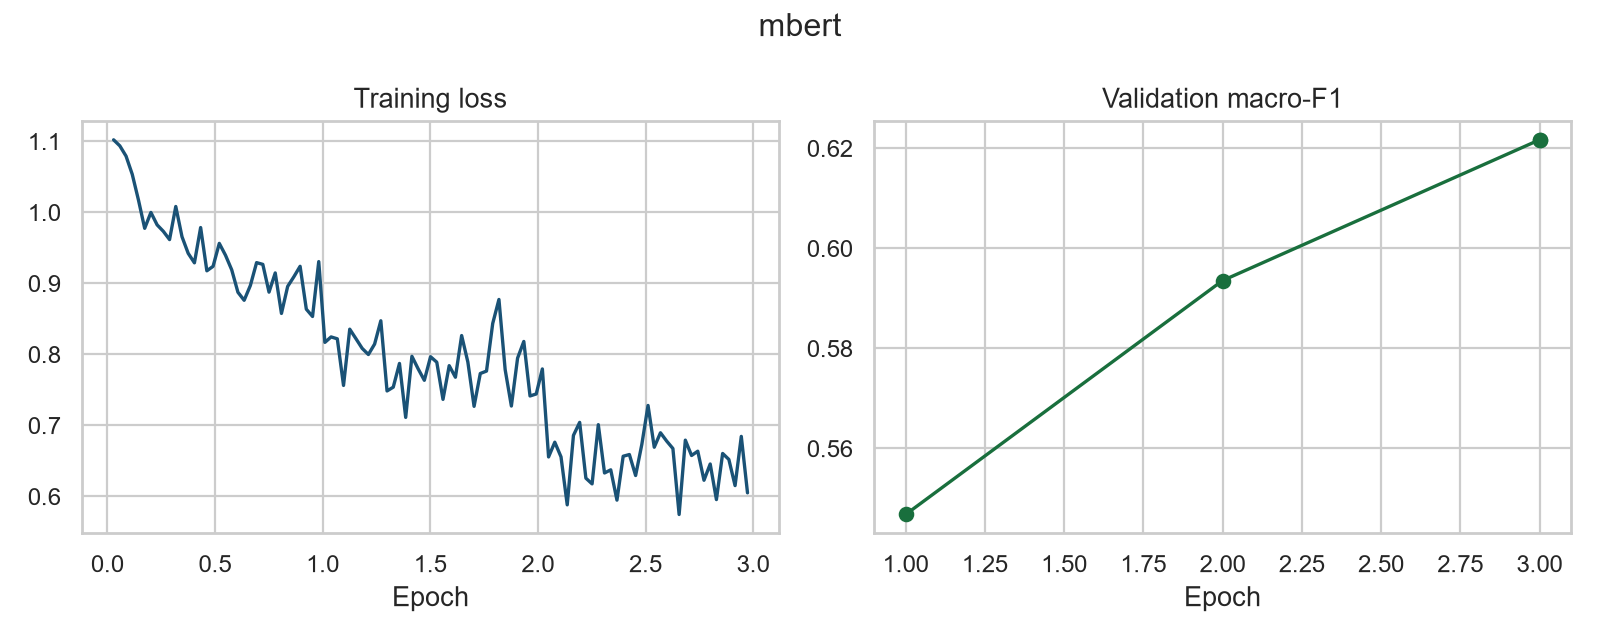

**curves_muril.png**

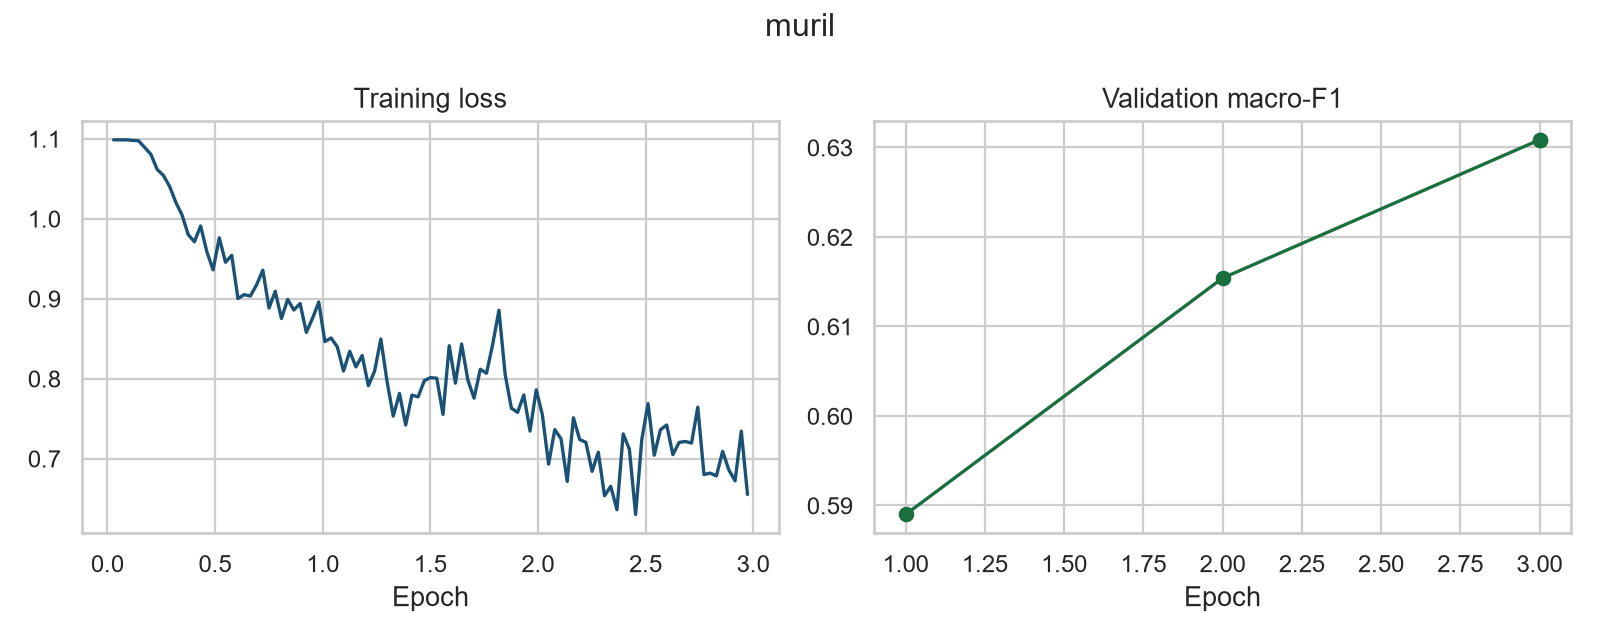

**curves_xlm-roberta.png**

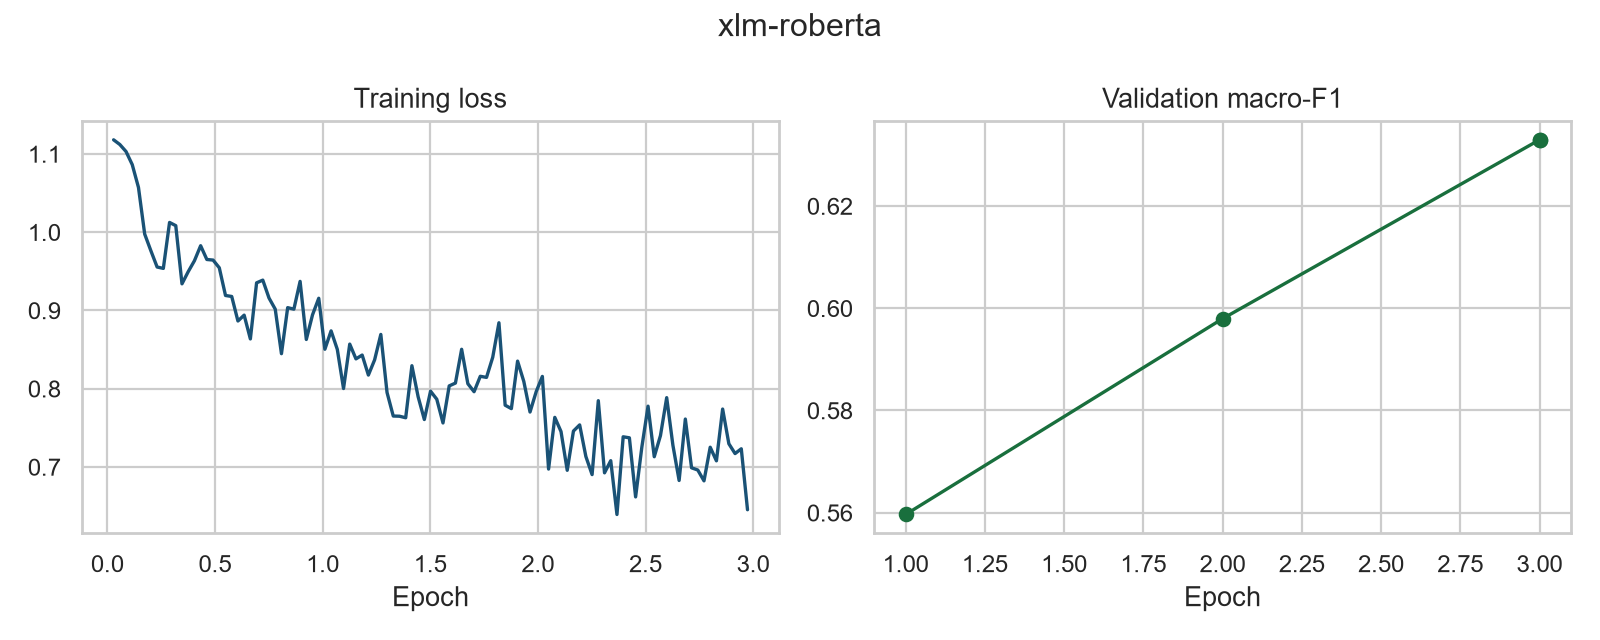

In [16]:
from IPython.display import display, Image, Markdown

plot_dir = Path(RESULTS) / "plots"
names = [
    "class_distribution.png",
    "length_histogram.png",
    "cmi_distribution.png",
    "top_words.png",
    "model_comparison.png",
]
names += sorted(p.name for p in plot_dir.glob("cm_*.png"))
names += sorted(p.name for p in plot_dir.glob("curves_*.png"))
seen = set()
for name in names:
    if name in seen:
        continue
    seen.add(name)
    path = plot_dir / name
    if path.exists():
        display(Markdown(f"**{name}**"))
        display(Image(filename=str(path)))


## 17. Errors

In [17]:
from IPython.display import display

counts = Path(RESULTS) / "errors_best_counts.csv"
errors = Path(RESULTS) / "errors_best.csv"
if counts.exists():
    display(pd.read_csv(counts))
if errors.exists():
    pd.set_option("display.max_colwidth", 160)
    display(pd.read_csv(errors).head(20))
else:
    print("errors_best.csv is written after the ablation cell.")


,linguistic_cause,count
0,Neutral-Sentiment Ambiguity,613
1,Spelling Variation / Character Elongation,111
2,Hindi Negation (Missed Polarity Flip),87
3,Complex Code-Switching / Mixed Sentiment,33


,index,text,true_label,predicted_label,confidence,linguistic_cause
0,78,Bhai ye to sahi h. mgr hamare pas h hi kya. Bjp ne to achut bna hi diya h. Nfrat bhir hi di logon ke dilon me. Khuda â€¦ https://t.co/QY5A9wAccl,positive,negative,0.4504,Complex Code-Switching / Mixed Sentiment
1,40,RT @tarani07615489 @PoliceRajasthan corruption ki complain pe aap dhayan Kyu nahi dete? Mene 2 baar tweet kiya ki jalor Police ( Ahore ) fr â€¦,negative,neutral,0.9027,Hindi Negation (Missed Polarity Flip)
2,4,RT @HardeepSPuri à¨¦à¨¾à¨¤à¨¾ à¨¸à©‹ à¨¸à¨¾à¨²à¨¾à¨¹à©€à¨ à¨œà¨¿ à¨¸à¨­à¨¸à©ˆ à¨¦à©‡ à¨†à¨§à¨¾à¨°à© à¥¥ Praise the Great Giver who gives sustenance to all...,positive,neutral,0.5578,Neutral-Sentiment Ambiguity
3,24,@Sicilian __ Mafia Bhaai Engineers sirf love hi krte hain. Wo love marriage mai convert naaai hoti,neutral,negative,0.5692,Spelling Variation / Character Elongation
4,108,Sab free kar dete hai sir sab bheekh maang kar jeeyege https://t.co/8vHkWztg9b,negative,positive,0.8055,Complex Code-Switching / Mixed Sentiment
5,54,@priyankagandhi Esa koi exam nahi up govt. M jo in 2 saal m leak na huaa hu Ye to sarkar ki rajniti h ki na to ham â€¦ https://t.co/S1s6PxoHiJ,negative,neutral,0.8272,Hindi Negation (Missed Polarity Flip)
6,19,@BaijnathMourya @mssirsa @AapkamanojS @ArvindKejriwal Haan Mai free Wi-Fi dunga free water dunga Sasti Bijli doo â€¦ https://t.co/d4uOIcb562,positive,neutral,0.9096,Neutral-Sentiment Ambiguity
7,50,Unse toh achchi hai yeh cigarette... dil ko jalati hai magar hoton pe toh aati hai.....ðŸ’”ðŸ’”ðŸ’” SMOKING AND LOVE BOTH C â€¦ https://t.co/rx1AYhkDCA,neutral,positive,0.8976,Spelling Variation / Character Elongation
8,458,* she breakup hurts the most.. * me kabhi Maa ko taklif me dekha hai.. #verypainful ðŸ˜”,negative,positive,0.6794,Complex Code-Switching / Mixed Sentiment
9,61,@narendramodi government job ke bare me sharkar ku responsible nahi vacancy itni kam aur vo final nahi kar va pa r â€¦ https://t.co/gdatpvcuFQ,negative,neutral,0.4815,Hindi Negation (Missed Polarity Flip)


## 18. Try a few lines

In [2]:
from src.predict import predict

samples = [
    "Bhai yeh movie sach me accha hai! 🔥",
    "Delivery itni late thi, bilkul bekaar service 😡",
    "Match kal shaam 7:30 baje start hoga.",
    "Ye phone lene ki galti mat karna, battery nahi chalti.",
    "Me acha nahi hu na",
    "Package deliver ho gaya hai but maine abhi open nahi kiya.",
]
for text in samples:
    out = predict(text)
    print(f"{out['label']:8}  {out['confidence']:.2f}  {out.get('flip', '')}")
    print(" ", text)
    print(" ", out.get("reading", ""))


c:\Collage\NLP\SEE project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1112 13:13:35.880000 32848 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


[Predictor] Loaded the character model and the scoped lexicon. No transformer is loaded.
positive  0.63  none
  Bhai yeh movie sach me accha hai! 🔥
  Gap 0.30. Specialist: character model. Trigger: movie. Character model says positive. Scoped lexicon says neutral. Scope: no polarity flip.
[Predictor] Loaded the character model and the scoped lexicon. No transformer is loaded.
neutral   0.62  none
  Delivery itni late thi, bilkul bekaar service 😡
  Gap 0.37. Specialist: both specialists. Trigger: itni. Character model says neutral. Scoped lexicon says neutral. Scope: no polarity flip.
[Predictor] Loaded the character model and the scoped lexicon. No transformer is loaded.
neutral   0.57  none
  Match kal shaam 7:30 baje start hoga.
  Gap 0.26. Specialist: both specialists. Trigger: hoga. Character model says neutral. Scoped lexicon says neutral. Scope: no polarity flip.
[Predictor] Loaded the character model and the scoped lexicon. No transformer is loaded.
negative  0.82  negation
  Ye